# Best GH

- Input parameters
  - Number of groups
  - Name ref variable
  - Name perf variable
 

- Options
  - Tree/graph search problem approach
     - Data structures:
         - Set of visited states
         - Priority queue sorted by minimum fitness function value
         - Attribute to keep the current best visited state
     
     - Initialization:
         - Based on the provided number of groups, obtain n-tiles per ref
         - Obtain mean perf value for each tile for each ref
         - Caclculate the mean perf std deviation of each tile across the refs
         - Fitness function: sum of tiles std. devs

     - Iteration:
         - Select the tile with the largest mean perf variance
         - Generate 2 new states:
           - Observation with highest positive std deviation within the tile*  is assigned to upper tile
           - Observation with lowest (highest negative) std deviation within the tile* is assigned to lower tile
         - Calculate fitness function for each new state
         - Check if new states yield better (lower) fitness function value than current 
         - Add both new states to a priroty queue based on their fitness function value
         - Add current state to visited states set
         - Advance to the (already prioritized) next state on queue

    *obtained by averaging the std dev of each obs across the tiles



  - Linear optimization problem approach
    - Minimize sum of tile's std_dev(X:bad) subject to a reasonable ordination(Y:score) across refs and tiles

# Auto GH

In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt


def plot_gh(df, ref, perf, gh, perf_denominator=None):
    #Plot GH distribution and performance over time.
    # Initiate subplots
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    # calculate percentage of GH by ref 
    df_count = df.groupby([ref, gh], as_index=False).apply( lambda x: pd.Series({"percentage": len(x)}))
    
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)[
        "percentage"
    ].transform(sum)
    
    # Plots GH distribution over time 
    df_count.pivot_table("percentage", ref, gh).plot( 
        kind="bar", stacked=True, ax=ax[0])
    ax[0].legend(loc="lower left")
    ax[0].set_title("GH distribution over time")
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].mean()
    else:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].sum()
        df_perf[perf] = ( df_perf[perf] /df.groupby([ref, gh]) [perf_denominator].sum().values)
        
    # Plots performance over time
    df_perf[ref] = df_perf[ref].astype(str)
    df_perf.pivot_table(perf, ref, gh).plot(ax=ax[1])
    ax[1].legend(loc="lower left")
    ax[1].set_title("Performance over time")

    # Calculate Log odds by ref and GH
    df_odds = (
        df.groupby([ref, gh]) .apply(lambda x: np.log( x[x[perf] > 0].shape[0] / x[~(x[perf] > 0)].shape[0]
    )).reset_index() .rename(columns={0: "log_odds"}))
    # Plots performance over time
    df_odds[ref] = df_odds[ref].astype(str) 
    df_odds.pivot_table("log_odds", ref, gh).plot(ax=ax[2])
    ax[2].legend(loc="lower left")
    ax[2].set_title("Log odds over time")
    # Rotate x labels
    for axis in ax: axis.tick_params(axis="x", labelrotation=90)
                                                           

In [2]:
def check_gh(
    df,
    ref,
    perf,
    gh,
    gh_min_size=0.05,
    z_min=2,
    perf_denominator=None
):
    # Calculate percentage of GH by ref 
    df_count = df.groupby(by=[ref, gh])[[ref, gh]].apply( lambda x: pd.Series({"percentage": len(x)}))
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)["percentage"].transform('sum')
    # print(df_count)
    df_count.reset_index(inplace=True)
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
    else: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
        df_perf[perf] = (df_perf[perf]/df.groupby([ref, gh])[perf_denominator].sum().values)

    # Generate the check report by GH and calculating 
    report = df_count.groupby(gh, as_index=False)[
        "percentage"
    ].mean() # Mean percentage by GH
    
    # Mean perf by GH
    report["mean_perf"] = df_perf.groupby(gh)[perf].mean().values
    #Std dev of perf by GH
    report["std_perf"] = df_perf.groupby(gh)[perf].std().values
    # Mean perf of previous GH
    report["mean_prev"] = report["mean_perf"].shift(1)
    # Std dev of perf of previous GH
    report["std_prev"] = report["std_perf"].shift(1)
    
    # Calculate z-score
    report["z"] = (report["mean_perf"] - report["mean_prev"]) / ((report["std_perf"] ** 2 + report["std_prev"] ** 2) ** 0.5)
    #Check column
    report["ok"] = (report["percentage"] > gh_min_size) & ((report["mean_prev"].isna()) | (report["z"] > z_min))
    # Set GH as index
    report = report.set_index(gh)
    return report

In [3]:
def get_cut_points(
    df,
    ref,
    perf,
    score,
    gh_min_size=0.05,
    z_min=2,
    step=0.01,
    perf_denominator=None
):
    # Initial cut points 
    cut_points = [0, 1]
    # Flag that indicates to continue 
    not_end = True
    # Instantiate progress bar 
    pbar = tqdm(total=len(np.arange(step, 1, step)), position=0, leave=True)
    
    while not_end:
        # Set flag to stop if no one new point be found 
        not_end = False
        # Loop thru every step 
        for i in np.arange(cut_points[-2] + step, 1, step):
            # Update progress bar
            pbar.update(1)
            # Insert new point in the end 
            new_cut_points = cut_points[:-1] + [i] + cut_points[-1:]
            # Create GH Labels 
            labels = np.arange(1, len(new_cut_points))
            # Create dataframe with GHS
            gh = pd.DataFrame(
                {"gh": pd.cut(df[score], bins=new_cut_points, labels=labels)}
            )
            
            # Check if all GHS are 'ok' with constraints
            df_check = check_gh(
                pd.concat([df, gh], axis=1),
                ref,
                perf,
                "gh",
                gh_min_size,
                z_min,
                perf_denominator,
            )
            
            if df_check["ok"].all():
                # Update cut points
                cut_points = new_cut_points
                # Set flat to continue looking for new cut points
                not_end = True
                break

    pbar.close()
    return [float(cp) for cp in cut_points] 

In [4]:
def get_gh(df, score, cut_points):
    ghs = pd.cut(
        df[score], 
        bins=cut_points,
        labels=np.arange(1, len(cut_points))
    )
    return ghs

In [5]:
import numpy as np
import pandas as pd
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=RuntimeWarning)

ref = [2306]*40 + [2307]*40 + [2308]*38
perf = [0]*50 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*8
score = [float(scr) for scr in np.linspace(0,1,118)]

In [6]:
np.random.seed(42)
np.random.shuffle(ref)
ref[:10]

[2307, 2308, 2306, 2307, 2306, 2308, 2307, 2306, 2308, 2307]

In [7]:
df = pd.DataFrame({'SAFRA': ref, 'PERF': perf, 'SCORE': score})

In [8]:
df.SAFRA.value_counts()

SAFRA
2307    40
2306    40
2308    38
Name: count, dtype: int64

In [9]:
df.groupby('SAFRA').SCORE.mean()

SAFRA
2306    0.461111
2307    0.491239
2308    0.550157
Name: SCORE, dtype: float64

In [10]:
df.groupby('SAFRA').PERF.mean()

SAFRA
2306    0.150000
2307    0.150000
2308    0.157895
Name: PERF, dtype: float64

In [11]:
df.head()

,SAFRA,PERF,SCORE
0,2307,0,0.000000
1,2308,0,0.008547
2,2306,0,0.017094
3,2307,0,0.025641
4,2306,0,0.034188


In [12]:
df['SAFRA']

0      2307
1      2308
2      2306
3      2307
4      2306
       ... 
113    2308
114    2306
115    2308
116    2307
117    2308
Name: SAFRA, Length: 118, dtype: int64

In [13]:
cp = get_cut_points(df,'SAFRA','PERF','SCORE',z_min=0.5, step=0.01)

 66%|████████████████████████████▏              | 65/99 [17:28<02:58,  5.24s/it]

KeyboardInterrupt: 

In [14]:
cp

[0.0, 0.060000000000000005, 0.4299999999999998, 0.5299999999999999, 0.65, 1.0]

In [15]:
df['GH'] = get_gh(df,'SCORE',cp)
df.GH.fillna(1,inplace=True)

In [16]:
df.GH.value_counts()

GH
2    43
5    41
4    14
3    12
1     8
Name: count, dtype: int64

In [17]:
pd.crosstab(df.GH,df.SAFRA)

SAFRA,2306,2307,2308
GH,,,
1,3,3,2
2,16,16,11
3,5,3,4
4,7,3,4
5,9,15,17


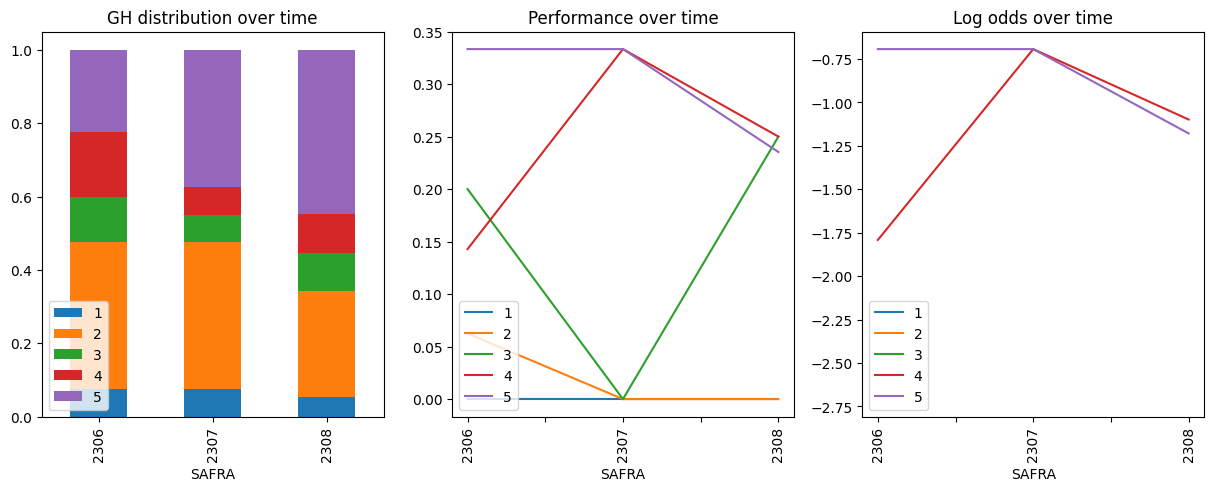

In [18]:
plot_gh(df, 'SAFRA', 'PERF', 'GH')

In [19]:
pd.crosstab(df.GH,df.SAFRA)

SAFRA,2306,2307,2308
GH,,,
1,3,3,2
2,16,16,11
3,5,3,4
4,7,3,4
5,9,15,17


In [20]:
df.groupby(['GH','SAFRA']).PERF.mean().unstack().sort_index(ascending=False)

SAFRA,2306,2307,2308
GH,,,
5,0.333333,0.333333,0.235294
4,0.142857,0.333333,0.250000
3,0.200000,0.000000,0.250000
2,0.062500,0.000000,0.000000
1,0.000000,0.000000,0.000000


In [22]:
df.loc[df.SAFRA==2308]

,SAFRA,PERF,SCORE,GH
1,2308,0,0.008547,1
5,2308,0,0.042735,1
8,2308,0,0.068376,2
11,2308,0,0.094017,2
13,2308,0,0.111111,2
16,2308,0,0.136752,2
18,2308,0,0.153846,2
19,2308,0,0.162393,2
22,2308,0,0.188034,2
28,2308,0,0.239316,2


In [23]:
# pd.DataFrame(np.hstack([df[df.SAFRA==ref].sort_values('SCORE') for ref in np.sort(df['SAFRA'].unique())]), columns=['SAFRA_1','PERF_1','SCORE_1','GH_1', 'SAFRA_2','PERF_2','SCORE_2','GH_2', 'SAFRA_3','PERF_3','SCORE_3','GH_3'])

# Best GH

In [24]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from pulp import *

In [25]:
safra = 'SAFRA'
perf = 'PERF'
score = 'SCORE'
gh = 'GH'
index = 'INDEX'
n_groups = 4

In [26]:
refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
refs_list

[2306, 2307, 2308]

In [27]:
groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
groups_list

[1, 2, 3, 4]

In [28]:
#idx_list = [str(i) for i in range(0,np.max([len(df[df[safra]==int(ref)]) for ref in refs_list]))]
idx_list = [[i+1 for i in range(0,len(df[df[safra]==ref]))] for ref in refs_list]
idx_list

[[1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38]]

In [29]:
idx_dict = {ref:[i for i in range(1,len(df[df[safra]==ref]) + 1)] for ref in refs_list}
idx_dict

{2306: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 2307: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 2308: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38]}

In [ ]:
# VI1G1R1 ==> assigning vars

# BADG1R1 => (VI1G1R1*PERF[I1,R1] + VI2G1R1*PERF[I2,R1] + VI3G1R1*PERF[I3,R1] ...) / (VI1G1R1 + VI2G1R1 + VI3G1R1 + ...)
# BADG2R1 => (VI1G2R1*PERF[I1,R1] + VI2G2R1*PERF[I2,R1] + VI3G2R1*PERF[I3,R1] ...) / (VI1G2R1 + VI2G2R1 + VI3G2R1 + ...)
# BADG3R1 => (VI1G3R1*PERF[I1,R1] + VI2G3R1*PERF[I2,R1] + VI3G3R1*PERF[I3,R1] ...) / (VI1G3R1 + VI2G3R1 + VI3G3R1 + ...)
# BADG4R1 => (VI1G4R1*PERF[I1,R1] + VI2G4R1*PERF[I2,R1] + VI3G4R1*PERF[I3,R1] ...) / (VI1G4R1 + VI2G4R1 + VI3G4R1 + ...)

# BADG1R2 => (VI1G1R2*PERF[I1,R2] + VI2G1R2*PERF[I2,R2] + VI3G1R2*PERF[I3,R2] ...) / (VI1G1R2 + VI2G1R2 + VI3G1R2 + ...)
# BADG2R2 => (VI1G2R2*PERF[I1,R2] + VI2G2R2*PERF[I2,R2] + VI3G2R2*PERF[I3,R2] ...) / (VI1G2R2 + VI2G2R2 + VI3G2R2 + ...)
# BADG3R2 => (VI1G3R2*PERF[I1,R2] + VI2G3R2*PERF[I2,R2] + VI3G3R2*PERF[I3,R2] ...) / (VI1G3R2 + VI2G3R2 + VI3G3R2 + ...)
# BADG4R2 => (VI1G4R2*PERF[I1,R2] + VI2G4R2*PERF[I2,R2] + VI3G4R2*PERF[I3,R2] ...) / (VI1G4R2 + VI2G4R2 + VI3G4R2 + ...)

# BADG1R3 => (VI1G1R3*PERF[I1,R3] + VI2G1R3*PERF[I2,R3] + VI3G1R3*PERF[I3,R3] ...) / (VI1G1R3 + VI2G1R3 + VI3G1R3 + ...)
# BADG2R3 => (VI1G2R3*PERF[I1,R3] + VI2G2R3*PERF[I2,R3] + VI3G2R3*PERF[I3,R3] ...) / (VI1G2R3 + VI2G2R3 + VI3G2R3 + ...)
# BADG3R3 => (VI1G3R3*PERF[I1,R3] + VI2G3R3*PERF[I2,R3] + VI3G3R3*PERF[I3,R3] ...) / (VI1G3R3 + VI2G3R3 + VI3G3R3 + ...)
# BADG4R3 => (VI1G4R3*PERF[I1,R3] + VI2G4R3*PERF[I2,R3] + VI3G4R3*PERF[I3,R3] ...) / (VI1G4R3 + VI2G4R3 + VI3G4R3 + ...)

# BADG1R1 = Z11 ==> CONSTRAINT ==> Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx) / SUM(assignment_vars[(1,1,idx)])
#                                  SUM(assignment_vars[(1,1,idx)]) * Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)

#                            U11 = SUM(assignment_vars[(1,1,idx)]) * Z11 ==> U11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)
#                                                                            U11 >= 0*Z11
#                                                                            U11 <= SUM(PERF[(1,idx)] for idx)*Z11

# -----------------------------------------------------------------------------------------------------------------------

# MEDG1 => (BADG1R1 + BADG1R2 + BADG1R3) * INVERSO_TOTAL_REFS
# MEDG2 => (BADG2R1 + BADG2R2 + BADG2R3) * INVERSO_TOTAL_REFS
# MEDG3 => (BADG3R1 + BADG3R2 + BADG3R3) * INVERSO_TOTAL_REFS
# MEDG4 => (BADG4R1 + BADG4R2 + BADG4R3) * INVERSO_TOTAL_REFS

# MEDG1 = Y1 ==> CONSTRAINT ==> TOTAL_REFS * Y1 = SOMA(Z11,Z12,Z13) 
# -----------------------------------------------------------------------------------------------------------------------

# STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
# STDDEVG2 => SOMA([|BADG2R1-MEDG2|,|BADG2R2-MEDG2|,|BADG2R3-MEDG2|]) * INVERSO_TOTAL_REFS
# STDDEVG3 => SOMA([|BADG3R1-MEDG3|,|BADG3R2-MEDG3|,|BADG3R3-MEDG3|]) * INVERSO_TOTAL_REFS
# STDDEVG4 => SOMA([|BADG4R1-MEDG4|,|BADG4R2-MEDG4|,|BADG4R3-MEDG4|]) * INVERSO_TOTAL_REFS

# STDDEVG1 = X1 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (|Z11-Y1| + |Z12-Y1| + |Z13-Y1|)
# |Z11-Y1| = W11 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (W11 + W12 + W13) 
#                                    Z11-Y1 <= W11
#                                    Y1-Z11 <= W11
# -----------------------------------------------------------------------------------------------------------------------

# MIN(STDDEVG1+STDDEVG2+STDDEVG3+STDDEVG4)

# MIN(X1+X2+X3+X4)

In [45]:
def generate_best_gh_problem(df, ref_var, perf_var, n_groups):
    refs_list = sorted([sfr for sfr in df[ref_var].unique()])
    groups_list = sorted([grp for grp in np.arange(1,n_groups+1)])
    idx_dict = {ref:[i for i in range(1,len(df[df[ref_var]==ref]) + 1)] for ref in refs_list}

    ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
    ref_idx_perf_dict = {(ref,i+1):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
    ref_idx_score_dict = {(ref,i+1):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
    
    n_idx_refs_dict = {ref:len(idx_dict[ref]) for ref in idx_dict}

    assignment_vars = {} # VIxGxRx
    for ref in refs_list:
        for grp in groups_list:            
            for idx in idx_dict[ref]:
                if idx < 10:
                    idx_str = f'0{idx}'
                else:
                    idx_str = f'{idx}'
                    
                assignment_vars[(ref,grp,idx)] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx_str}', cat=LpBinary)

    
    qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpInteger)
    
    bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, 1, LpContinuous)

    med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)

    desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)
    
    desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)

    

    
    prob = LpProblem("BestGH", LpMinimize)
    
    prob += (
        lpSum([desvio_medio_vars[grp] for grp in groups_list]),
        "SomadosDesviosMediosdasBadRatesDosGHsAoLongoDasRefs",
    )
    
    # RESTRIÇÕES DO DESVIO MÉDIO
    for grp in groups_list:
        prob += (
            len(refs_list)*desvio_medio_vars[grp] == lpSum([desvio_absoluto_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoDesvioMedio_grp_{grp}",
        )

    # RESTRIÇÕES DO DESVIO ABSOLUTO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                bad_vars[ref][grp] - med_vars[grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(1)_grp_{grp}_ref_{ref}"
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                med_vars[grp] - bad_vars[ref][grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(2)_grp_{grp}_ref_{ref}"
            )


    
    # RESTRIÇÕES DA MÉDIA
    for grp in groups_list:
        prob += (
            len(refs_list)*med_vars[grp] == lpSum([bad_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoMedia_grp_{grp}",
        )
        

    # RESTRIÇÕES DAS VARIÁVEIS DE ATRIBUIÇÃO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp]  == lpSum([assignment_vars[ref,grp,idx]*ref_idx_perf_dict[(ref,idx)] for idx in idx_dict[ref]]) ,
                f"DefinicaoVariaveisAtribuicao(1)_grp_{grp}_ref_{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] >= 0,
                f"DefinicaoVariaveisAtribuicao(2)_grp_{grp}_ref_{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] <= lpSum([ref_idx_perf_dict[(ref,idx)] for idx in idx_dict[ref]]) * bad_vars[ref][grp],
                f"DefinicaoVariaveisAtribuicao(3)_grp_{grp}_ref_{ref}",
            )   
    



    
    # RESTRIÇÃO ATRIBUIÇÃO A SOMENTE 1 GRUPO
    for ref in refs_list:
        for idx in idx_dict[ref]:
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) == 1,
                f"CadaPontoAtribuidoASomente1Grupo_ref_{ref}_idx_{idx}",
            )    

    # RESTRIÇÃO ATRIBUIÇÃO A PELO MENOS 1 GRUPO
    for ref in refs_list:
        for grp in groups_list:    
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref]]) >= 2,
                f"CadaGrupoPeloMenos1Membro_r{ref}_g{grp}_i{idx}",
            )

    # RESTRIÇÃO DE COMPLETUDE: PARA CADA REF, TODO E CADA UM DOS INDICES É ATRIBUÍDO A UM GRUPO            
    for ref in refs_list:    
        prob += (
            lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref] for grp in groups_list]) == len(idx_dict[ref]),
            f"TotalIndicesPorRef_r{ref}",
        )

    # RESTRIÇÃO DE ORDENAÇÃO DAS MÉDIAS: A MÉDIA DOS VALORES DE BAD RATE AO LONGO DAS REFS PARA O GRUPO 1 DEVE SER MENOR QUE A DO GRUPO 2. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for grp in groups_list[:-1]:
        prob += (
            med_vars[grp] <= med_vars[grp+1],
            f"OrdemMediaGrupos_grp_{grp}"
        )

    # RESTRIÇÃO DE ORDENAÇÃO DAS BAD RATES: PARA UMA MESMA REF, O VALOR DE BAD RATE DO GRUPO 1 DEVE SER MENOR QUE O DO GRUPO 2. O DO GRUPO 2, MENOR QUE O DO GRUPO 3 E ETC...
    for ref in refs_list:
        for grp in groups_list[:-1]:    
            prob += (
                bad_vars[ref][grp] <= bad_vars[ref][grp+1],
                f"OrdemBadGrupos_grp_{grp}_ref_{ref}"
            )

    # RESTRIÇÃO DE NÃO CRUZAMENTO DAS BAD RATES: PARA UMA DETERMINADA REF, A BAD RATE DO GRUPO 1 DEVE SER SEMPRE MENOR QUE A BAD RATE DO GRUPO 2 PARA TODAS AS DEMAIS REFS. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for ref in refs_list:
        #other_refs_list = list(set(refs_list.copy()) - set(ref))
        for grp in groups_list[:-1]:    
            for ref2 in refs_list:
                prob += (
                    bad_vars[ref][grp] <= bad_vars[ref2][grp+1],
                    f"NaoCruzamentoBadGrupos_g{grp}_r{ref}_r{ref2}"
                )

    
    # RESTRIÇÃO SCORES ORDENADOS: INDICE 1 POSSUI O MENOR VALOR DE SCORE E INDICE N POSSUI O MAIOR
    for ref in refs_list:
        for idx in idx_dict[ref][:-1]:            
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) * ref_idx_score_dict[(ref,idx)] <= lpSum([assignment_vars[ref,grp,idx+1] for grp in groups_list]) * ref_idx_score_dict[(ref,idx+1)],
                f"ScoresPermanecemOrdenados_ref_{ref}_idx_{idx}",
            )


    # # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, OS MENORES INDICES PERTENCEM AO 1o GRUPO, OS SEGUINTES AO 2o, etc...
    # for ref in refs_list:
    #     for i, grp in enumerate(groups_list,start=1):
    #         for idx in idx_dict[ref]:
    #             prob += (
    #                 assignment_vars[ref,grp,idx] >= lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) - big_M*(1-assignment_vars[ref,grp,idx]),
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, OS MENORES INDICES PERTENCEM AO 1o GRUPO, OS SEGUINTES AO 2o, etc...
    for ref in refs_list:
        big_M = n_idx_refs_dict[ref]
        for grp in groups_list:
            for i, idx in enumerate(idx_dict[ref][:-1]):
                # print(f'idx = {idx}')
                # print(f'idx + 1 = {idx+1}')
                # print(f'idx maiores = {[idx2 for idx2 in idx_dict[ref][(i+1):]]}')
                prob += (
                    assignment_vars[ref,grp,idx] - 1 + big_M*(1 - assignment_vars[ref,grp,idx])  >= lpSum([assignment_vars[ref,grp,idx2] for idx2 in idx_dict[ref][(i+1):]]) - big_M*(assignment_vars[ref,grp,idx+1]) ,
                    f"PreencherGruposMenorProMaiorIndice(1)_r{ref}_g{grp}_i{idx}",
                )# VRGI1 + big_M*(1 - VRGI1)  >= (VRGI2+VRGI3+...+VRGIN) - big_M*(VRGI2)
                 # - Se VRGI1 == 0 e VRGI2 == 0   ==>   0 + big_M >=  (VRGI2+VRGI3+...+VRGIN) - 0
                 #                                ==>   big_M >=  (VRGI2+VRGI3+...+VRGIN)
                )# - Se VRGI1 == 0 e VRGI2 == 1   ==>   0 + big_M >=  (VRGI2+VRGI3+...+VRGIN) - 0
                 #                                ==>   big_M >=  (VRGI2+VRGI3+...+VRGIN)
    for ref in refs_list:
        big_M = n_idx_refs_dict[ref]
        for grp in groups_list:
            for i, idx in enumerate(idx_dict[ref][:-1]):
                prob += (
                    assignment_vars[ref,grp,idx+1] - 1 + big_M*(assignment_vars[ref,grp,idx])  >= lpSum([assignment_vars[ref,grp,idx2] for idx2 in idx_dict[ref][:(i+1)]]) - big_M*(1 - assignment_vars[ref,grp,idx+1]) ,
                    f"PreencherGruposMenorProMaiorIndice(2)_r{ref}_g{grp}_i{idx}",
                )

    
    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, O 1o GRUPO É PREENCHIDO PELOS MENORES INDICES, EM SEGUIDA O 2o GRUPO É PREENCHIDO COM OS INDICES SUBSEQUENTES, ETC...
    for ref in refs_list:
        for idx in idx_dict[ref]:
            for i, grp in enumerate(groups_list[:-1]):
                prob += (
                    assignment_vars[ref,grp,idx] - 1 + n_groups*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,grp2,idx] for grp2 in groups_list[(i+1):]]),
                    f"PreencherGruposMenorProMaiorGrupo(1)_r{ref}_g{grp}_i{idx}",
                )


    for ref in refs_list:
        for idx in idx_dict[ref]:
            for i, grp in enumerate(groups_list[:-1]):
                prob += (
                    assignment_vars[ref,grp+1,idx] - 1 + n_groups*(assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,grp2,idx] for grp2 in groups_list[(i+1):]]),
                    f"PreencherGruposMenorProMaiorGrupo(2)_r{ref}_g{grp}_i{idx}",
                )

    
    

    for ref in refs_list:    
        assignment_vars[ref,1,1].setInitialValue(1)
        assignment_vars[ref,1,1].fixValue()

    
    return prob, assignment_vars



    # for ref in refs_list:
    #     for grp in groups_list:
    #         for idx in idx_dict[ref][:-1]:
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) >= assignment_vars[ref,grp,str(int(idx)+1)],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )    
    

    # # O GRUPO DO INDICE i É MENOR QUE O GRUPO DO ÍNDICE i+1 PARA TODO ÍNDICE PARA UMA MESMA REF
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for idx in idx_dict[ref][:-1]:
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 int(grp)*assignment_vars[ref,grp,idx] <= (int(grp))*assignment_vars[ref,grp,str(int(idx)+1)],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )
    
    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,str(grp),idx] for grp in groups_list]),
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )

    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 idx*assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) <= assignment_vars[ref,str(int(grp)+1),idx],
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )

    # # TODO INDICE DO G1 É MENOR QUE TODO INDICE DO G2 PARA UMA MESMA REF 
    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 int(idx)*assignment_vars[ref,grp,idx] <= int(idx)*assignment_vars[ref,str(int(grp)+1),idx],
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )
    
    # for ref in refs_list:
    #     for idx in idx_dict[ref][:-1]:            
    #         # RESTRIÇÃO ÍNDICES ORDENADOS
    #         prob += (
    #             lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) <= lpSum([assignment_vars[ref,grp,str(int(idx)+1)] for grp in groups_list]) * ref_idx_score_dict[(ref,str(int(idx)+1))],
    #             f"ScoresPermanecemOrdenados_ref_{ref}_idx_{idx}",
    #         )

    # # O GRUPO DO INDICE i É MENOR QUE O GRUPO DO ÍNDICE i+1 PARA TODO ÍNDICE PARA UMA MESMA REF
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for i, idx in enumerate(idx_dict[ref][:-1]):
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + len(idx_dict[ref])*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref][(i+1):]]),
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

    # for ref in refs_list:
    #     for idx in idx_dict[ref][:-1]:
    #         for i, grp in enumerate(groups_list[:-1]):
    #             prob += (
    #                 lpSum([assignment_vars[ref,grp,idx] for grp in groups_list[i:]]) >= lpSum([assignment_vars[ref,grp,idx] for grp in groups_list[i+1:]]),
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )



    
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for i, idx in enumerate(idx_dict[ref][:-1]):
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + 100*(1-assignment_vars[ref,grp,idx]) >= assignment_vars[ref,grp,idx+1],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

In [54]:
#     # VIXG1RX + VIXG2RX + VIXG3RX + VIXG4RX = 1 PARA TODO I, PARA TODO R
#     # (VI1G1RX + VI1G2RX + VI1G3RX + VI1G4RX)*SCORE[Ix,RX] < (VIx+1G1RX + VIx+1G2RX + VI2G3RX + VI2G4RX)*SCORE[Ix+1,RX] PARA TODO I, PARA TODO R
#     # VI2GxRx < 1 - VI1GxRx PARA TODO G PARA TODO R
#     # VIxG2Rx < 1 - VIxG1Rx PARA TODO I PARA TODO R


# if score1 < score2 then grp1 < grp2

#                  Na transicao de grupo == 1 senão 0
# IDX TROCA GRUPO = (VIyG1Rx-VIy+1G1Rx)*(Iy) todos indicadores abaixo do indice y são maiores que todos acima
# (I2)*VI2G1Rx >= (I3)*VI3G2Rx

# o indice dos V do grupo 1 são menores que o indice dos V do grupo 2

In [55]:
# y1 é IDX TROCA GRUPO1 = (VIyG1R-VIy+1G1R)*(Iy)
# y2 é IDX TROCA GRUPO2 = (VIyG2R-VIy+1G2R)*(Iy)
# y3 é IDX TROCA GRUPO3 = (VIyG3R-VIy+1G3R)*(Iy)
# y4 é IDX TROCA GRUPO4 = (VIyG4R-VIy+1G4R)*(Iy)

# se I < y1 ==> VIyG1R > VIyG2R
#               VIyG1R > VIyG3R
#               VIyG1R > VIyG4R
# se y1 < I < y2 ==> VIyG2R > VIyG3R
#                    VIyG2R > VIyG4R
# se y2 < I < y3 ==> VIyG3R > VIyG4R


# for i in idx_list:

# soma(VIxG1R + VIxG2R + VIxG3R + VIxG4R) - 1  <= 1*(VIxG1R)

# soma(VIxG2R + VIxG3R + VIxG4R) <= (VIxG1R)

In [56]:
# X = desvio médio
# W = desvio absoluto
# Y = media
# Z = bad
# V = vars atribuicao
# U = numerador bad

In [46]:
safra = 'SAFRA'
perf = 'PERF'
score = 'SCORE'
gh = 'GH'
index = 'INDEX'
n_groups = 4

In [47]:
prob, assignment_vars = generate_best_gh_problem(df, safra, perf, n_groups)

# refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
# groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
# idx_dict = {ref:[int(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}

refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
idx_dict = {ref:[i for i in range(1,len(df[df[safra]==ref]) + 1)] for ref in refs_list}

ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(ref,i+1):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_score_dict = {(ref,i+1):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

# ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
# ref_idx_perf_dict = {(ref,int(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,int(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
#ref_idx_perf_dict
#desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

In [48]:
prob

BestGH:
MINIMIZE
1*desvio_medio_grp_1 + 1*desvio_medio_grp_2 + 1*desvio_medio_grp_3 + 1*desvio_medio_grp_4 + 0
SUBJECT TO
DefinicaoDesvioMedio_grp_1: - desvio_absoluto_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2307_1 - desvio_absoluto_ref_grp_2308_1
 + 3 desvio_medio_grp_1 = 0

DefinicaoDesvioMedio_grp_2: - desvio_absoluto_ref_grp_2306_2
 - desvio_absoluto_ref_grp_2307_2 - desvio_absoluto_ref_grp_2308_2
 + 3 desvio_medio_grp_2 = 0

DefinicaoDesvioMedio_grp_3: - desvio_absoluto_ref_grp_2306_3
 - desvio_absoluto_ref_grp_2307_3 - desvio_absoluto_ref_grp_2308_3
 + 3 desvio_medio_grp_3 = 0

DefinicaoDesvioMedio_grp_4: - desvio_absoluto_ref_grp_2306_4
 - desvio_absoluto_ref_grp_2307_4 - desvio_absoluto_ref_grp_2308_4
 + 3 desvio_medio_grp_4 = 0

DefinicaoDesvioAbsoluto(1)_grp_1_ref_2306: bad_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2306_1 - media_grp_1 <= 0

DefinicaoDesvioAbsoluto(1)_grp_1_ref_2307: bad_ref_grp_2307_1
 - desvio_absoluto_ref_grp_2307_1 - media_grp_1 <= 0

DefinicaoDesvioAbs

In [49]:
prob.solve()

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /home/thommic/Python/venvs/best_gh/lib64/python3.12/site-packages/pulp/solverdir/cbc/linux/64/cbc /tmp/97c5807081314fd2a7ed6590f588f786-pulp.mps -timeMode elapsed -branch -printingOptions all -solution /tmp/97c5807081314fd2a7ed6590f588f786-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 1988 COLUMNS
At line 26743 RHS
At line 28727 BOUNDS
At line 29224 ENDATA
Problem MODEL has 1983 rows, 516 columns and 23428 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Problem is infeasible - 0.01 seconds
Option for printingOptions changed from normal to all
Total time (CPU seconds):       0.02   (Wallclock seconds):       0.02



-1

In [36]:
for var in prob.variables():
    print(f'Var: {var} | Value: {var.value()}')

Var: bad_ref_grp_2306_1 | Value: 0.5
Var: bad_ref_grp_2306_2 | Value: 0.5
Var: bad_ref_grp_2306_3 | Value: 0.5
Var: bad_ref_grp_2306_4 | Value: 0.5
Var: bad_ref_grp_2307_1 | Value: 0.5
Var: bad_ref_grp_2307_2 | Value: 0.5
Var: bad_ref_grp_2307_3 | Value: 0.5
Var: bad_ref_grp_2307_4 | Value: 0.5
Var: bad_ref_grp_2308_1 | Value: 0.5
Var: bad_ref_grp_2308_2 | Value: 0.5
Var: bad_ref_grp_2308_3 | Value: 0.5
Var: bad_ref_grp_2308_4 | Value: 0.5
Var: desvio_absoluto_ref_grp_2306_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_4 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_4 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_3 | Value: 0.0
Var: desvio_absol

In [37]:
for const in prob.constraints:
    print(f'Constraint: {const} | Value: {prob.constraints[const].value()}')

Constraint: DefinicaoDesvioMedio_grp_1 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_2 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_3 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_4 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2308 |

In [38]:
prob.constraints[list(prob.constraints.keys())[0]].value()

0.0

In [39]:
solution_dict = {}

for ref in refs_list:
    solution_dict[int(ref)] = {}
    
    for grp in groups_list:
        solution_dict[int(ref)][int(grp)] = []
        
        for idx in idx_dict[ref]:
            if assignment_vars[int(ref),int(grp),int(idx)].value() == 1:
                solution_dict[int(ref)][int(grp)].append(idx)

In [40]:
solution_dict

{2306: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34],
  2: [35, 36],
  3: [39, 40],
  4: [37, 38]},
 2307: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34],
  2: [39, 40],
  3: [35, 36],
  4: [37, 38]},
 2308: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27],
  2: [28, 29],
  3: [30, 31, 32, 33, 34, 35, 36],
  4: [37, 38]}}

In [41]:
grp_ref_bad_rate = {}
grp_bad_mean = {}
grp_std_dev = {}

for ref in refs_list:
    grp_ref_bad_rate[ref] = {}
    for grp in groups_list:
        grp_ref_bad_rate[int(ref)][int(grp)] = []
        for idx in solution_dict[int(ref)][int(grp)]:
            grp_ref_bad_rate[int(ref)][int(grp)].append(ref_idx_perf_dict[ref,idx])
        grp_ref_bad_rate[int(ref)][int(grp)] = 0 if len(grp_ref_bad_rate[int(ref)][int(grp)]) == 0 else float(np.sum(grp_ref_bad_rate[int(ref)][int(grp)])/len(grp_ref_bad_rate[int(ref)][int(grp)]))

for grp in groups_list:
    grp_bad_mean[int(grp)] = []
    for ref in refs_list:
        grp_bad_mean[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_bad_mean[int(grp)] = float(np.sum(grp_bad_mean[int(grp)])/len(grp_bad_mean[int(grp)]))


for grp in groups_list:
    grp_std_dev[int(grp)] = []
    for ref in refs_list:
        grp_std_dev[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_std_dev[int(grp)] = float(np.std(grp_std_dev[int(grp)]))

# for grp in groups_list:
#     grp_std_dev[grp] = []
#     for ref in refs_list:
#         grp_std_dev[grp].append(grp_bad_mean[grp])
#     grp_std_dev[grp] = np.std(grp_std_dev[grp])

# STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
# ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

# 

## grp_ref_bad_rate

In [43]:
grp_bad_mean

{1: 0.08605664488017428, 2: 0.5, 3: 0.5476190476190476, 4: 0.5}

In [44]:
grp_std_dev

{1: 0.021401833011316446,
 2: 0.408248290463863,
 3: 0.35154340619603336,
 4: 0.408248290463863}

In [139]:
refs_list = sorted([str(sfr) for sfr in df[safra].unique()])
groups_list = sorted([str(grp) for grp in np.arange(1,n_groups+1)])
idx_dict = {ref:[str(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}

ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

#inverse_total_grps = 1/n_groups
n_idx_refs_dict = {ref:len(idx_dict[ref]) for ref in idx_dict}


assignment_vars = {} # VIxGxRx
#order_indicator_vars = {} # T
for ref in refs_list:
    for grp in groups_list:
        #zip_idx = [(i,x) for i,x in zip(idx_dict[ref][:-1],idx_dict[ref][1:])]
        
        for idx in idx_dict[ref]:
            assignment_vars[(str(ref),str(grp),str(idx))] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx}', cat=LpBinary)

        #for idx1,idx2 in zip_idx:
        #    order_indicator_vars[(ref,grp,idx1,idx2)] = LpVariable(f'ref_{ref}_grp_{grp}_T_{idx1}_{idx2}', cat=LpBinary)

qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)

desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)

## SOLUÇÃO ALTERNATIVA

In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from pulp import *

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=RuntimeWarning)

ModuleNotFoundError: No module named 'pulp'

In [2]:
ref = [2306]*40 + [2307]*40 + [2308]*38
perf = [0]*50 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*8
score = [float(scr) for scr in np.linspace(0,1,118)]

In [3]:
np.random.seed(42)
np.random.shuffle(ref)
ref[:10]

[2307, 2308, 2306, 2307, 2306, 2308, 2307, 2306, 2308, 2307]

In [4]:
df = pd.DataFrame({'SAFRA': ref, 'PERF': perf, 'SCORE': score})

In [5]:
df.SAFRA.value_counts()

SAFRA
2307    40
2306    40
2308    38
Name: count, dtype: int64

In [6]:
df.groupby('SAFRA').SCORE.mean()

SAFRA
2306    0.461111
2307    0.491239
2308    0.550157
Name: SCORE, dtype: float64

In [7]:
df.groupby('SAFRA').PERF.mean()

SAFRA
2306    0.150000
2307    0.150000
2308    0.157895
Name: PERF, dtype: float64

In [8]:
df.head()

,SAFRA,PERF,SCORE
0,2307,0,0.000000
1,2308,0,0.008547
2,2306,0,0.017094
3,2307,0,0.025641
4,2306,0,0.034188


In [218]:
safra = 'SAFRA'
perf = 'PERF'
score = 'SCORE'
gh = 'GH'
index = 'INDEX'
n_groups = 3

In [219]:
refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
refs_list

[2306, 2307, 2308]

In [220]:
groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
groups_list

[1, 2, 3]

In [221]:
idx_list = [i+1 for i in range(0,len(df[score]))]

In [222]:
ref_idx_indicator_dict = {}
for ref in refs_list:
    refs_series = np.where(df[safra] == ref, 1, 0)
    for i, ind in enumerate(refs_series):
        ref_idx_indicator_dict[(ref, i)] = int(ind)

ref_idx_indicator_dict

{(2306, 0): 0,
 (2306, 1): 0,
 (2306, 2): 1,
 (2306, 3): 0,
 (2306, 4): 1,
 (2306, 5): 0,
 (2306, 6): 0,
 (2306, 7): 1,
 (2306, 8): 0,
 (2306, 9): 0,
 (2306, 10): 1,
 (2306, 11): 0,
 (2306, 12): 1,
 (2306, 13): 0,
 (2306, 14): 0,
 (2306, 15): 1,
 (2306, 16): 0,
 (2306, 17): 1,
 (2306, 18): 0,
 (2306, 19): 0,
 (2306, 20): 0,
 (2306, 21): 0,
 (2306, 22): 0,
 (2306, 23): 0,
 (2306, 24): 0,
 (2306, 25): 1,
 (2306, 26): 1,
 (2306, 27): 0,
 (2306, 28): 0,
 (2306, 29): 1,
 (2306, 30): 0,
 (2306, 31): 1,
 (2306, 32): 1,
 (2306, 33): 0,
 (2306, 34): 0,
 (2306, 35): 1,
 (2306, 36): 0,
 (2306, 37): 0,
 (2306, 38): 1,
 (2306, 39): 1,
 (2306, 40): 0,
 (2306, 41): 0,
 (2306, 42): 1,
 (2306, 43): 0,
 (2306, 44): 0,
 (2306, 45): 1,
 (2306, 46): 0,
 (2306, 47): 0,
 (2306, 48): 1,
 (2306, 49): 0,
 (2306, 50): 1,
 (2306, 51): 1,
 (2306, 52): 0,
 (2306, 53): 1,
 (2306, 54): 0,
 (2306, 55): 1,
 (2306, 56): 0,
 (2306, 57): 0,
 (2306, 58): 0,
 (2306, 59): 1,
 (2306, 60): 1,
 (2306, 61): 0,
 (2306, 62): 0,
 (

In [223]:
indicators_refs = {ref:np.where(df[safra] == ref, 1, 0) for ref in refs_list}
ref_idx_indicator_dict = {(ref, i+1): int(ind) for ref in refs_list for i, ind in enumerate(indicators_refs[ref])} 
#ref_idx_indicator_dic

In [224]:
# VI1G1 ==> assigning vars

# BADG1R1 => (VI1G1*IND[R1,I1]*PERF[I1] + VI2G1*IND[R1,I2]*PERF[I2] + VI3G1*IND[R1,I3]*PERF[I3] ...) / (VI1G1*IND[R1,I1] + VI2G1*IND[R1,I2] + VI3G1*IND[R1,I3] + ...)
# BADG2R1 => (VI1G2*IND[R1,I1]*PERF[I1] + VI2G2*IND[R1,I2]*PERF[I2] + VI3G2*IND[R1,I3]*PERF[I3] ...) / (VI1G2*IND[R1,I1] + VI2G2*IND[R1,I2] + VI3G2*IND[R1,I3] + ...)
# BADG3R1 => (VI1G3*IND[R1,I1]*PERF[I1] + VI2G3*IND[R1,I2]*PERF[I2] + VI3G3*IND[R1,I3]*PERF[I3] ...) / (VI1G3*IND[R1,I1] + VI2G3*IND[R1,I2] + VI3G3*IND[R1,I3] + ...)
# BADG4R1 => (VI1G4*IND[R1,I1]*PERF[I1] + VI2G4*IND[R1,I2]*PERF[I2] + VI3G4*IND[R1,I3]*PERF[I3] ...) / (VI1G4*IND[R1,I1] + VI2G4*IND[R1,I2] + VI3G4*IND[R1,I3] + ...)

# BADG11 = Z11 ==> CONSTRAINT ==> Z11 = SUM(assignment_vars[(G1,idx)]*IND[R1,idx]*PERF[idx] for idx) / SUM(assignment_vars[(R1,idx)]*IND[R1,idx])
#                                       SUM(assignment_vars[(G1,idx)]*IND[R1,idx]) * Z11 = SUM(assignment_vars[(G1,idx)]*IND[R1,idx]*PERF[idx] for idx)

#                                 U11 = SUM(assignment_vars[(G1,idx)]*IND[R1,idx]) * Z11 ==> U11 = SUM(assignment_vars[(R1,idx)]*IND[R1,idx]*PERF[idx] for idx)
#                                                                                            U11 >= 0*Z11
#                                                                                            U11 <= SUM(PERF[idx]*IND[R1,idx] for idx)*Z11

# -----------------------------------------------------------------------------------------------------------------------

# MEDG1 => (BADG1R1 + BADG1R2 + BADG1R3) * INVERSO_TOTAL_REFS
# MEDG2 => (BADG2R1 + BADG2R2 + BADG2R3) * INVERSO_TOTAL_REFS
# MEDG3 => (BADG3R1 + BADG3R2 + BADG3R3) * INVERSO_TOTAL_REFS
# MEDG4 => (BADG4R1 + BADG4R2 + BADG4R3) * INVERSO_TOTAL_REFS

# MEDG1 = Y1 ==> CONSTRAINT ==> TOTAL_REFS * Y1 = SOMA(Z11,Z12,Z13) 
# -----------------------------------------------------------------------------------------------------------------------

# STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
# STDDEVG2 => SOMA([|BADG2R1-MEDG2|,|BADG2R2-MEDG2|,|BADG2R3-MEDG2|]) * INVERSO_TOTAL_REFS
# STDDEVG3 => SOMA([|BADG3R1-MEDG3|,|BADG3R2-MEDG3|,|BADG3R3-MEDG3|]) * INVERSO_TOTAL_REFS
# STDDEVG4 => SOMA([|BADG4R1-MEDG4|,|BADG4R2-MEDG4|,|BADG4R3-MEDG4|]) * INVERSO_TOTAL_REFS

# STDDEVG1 = X1 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (|Z11-Y1| + |Z12-Y1| + |Z13-Y1|)
# |Z11-Y1| = W11 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (W11 + W12 + W13) 
#                                    Z11-Y1 <= W11
#                                    Y1-Z11 <= W11
# -----------------------------------------------------------------------------------------------------------------------

# MIN(STDDEVG1+STDDEVG2+STDDEVG3+STDDEVG4)

# MIN(X1+X2+X3+X4)

In [225]:
def generate_best_gh_problem(df, ref_var, perf_var, score_var, n_groups):
    refs_list = sorted([sfr for sfr in df[ref_var].unique()])
    groups_list = sorted([grp for grp in np.arange(1,n_groups+1)])
    idx_list = [i+1 for i in range(0,len(df[score]))]

    #ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
    n_idx_refs_dict = {ref:int(df[ref_var].value_counts().loc[ref]) for ref in refs_list}
    
    indicators_refs = {ref:np.where(df[ref_var] == ref, 1, 0) for ref in refs_list}
    ref_idx_indicator_dict = {(ref,i+1):int(ind) for ref in refs_list for i, ind in enumerate(indicators_refs[ref])}     
    idx_perf_dict = {i+1:int(df[perf_var].loc[i]) for i in df.index}
    idx_score_dict = {i+1:float(df[score_var].loc[i]) for i in df.index}
    

    assignment_vars = {} # VIxGx
    for grp in groups_list:            
        for idx in idx_list:
            if idx < 10:
                idx_str = f'0{idx}'
            else:
                idx_str = f'{idx}'
                
            assignment_vars[(grp,idx)] = LpVariable(f'g{grp}_i{idx_str}', cat=LpBinary)


    
    qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpInteger)
    bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, 1, LpContinuous)
    med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)
    desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)
    desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)

    
    prob = LpProblem("BestGH", LpMinimize)
    
    prob += (
        lpSum([desvio_medio_vars[grp] for grp in groups_list]),
        "SomadosDesviosMediosdasBadRatesDosGHsAoLongoDasRefs",
    )
    
    # RESTRIÇÕES DO DESVIO MÉDIO
    for grp in groups_list:
        prob += (
            len(refs_list)*desvio_medio_vars[grp] == lpSum([desvio_absoluto_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoDesvioMedio_g{grp}",
        )

    # RESTRIÇÕES DO DESVIO ABSOLUTO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                bad_vars[ref][grp] - med_vars[grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(1)_g{grp}_r{ref}"
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                med_vars[grp] - bad_vars[ref][grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(2)_g{grp}_r{ref}"
            )


    
    # RESTRIÇÕES DA MÉDIA
    for grp in groups_list:
        prob += (
            len(refs_list)*med_vars[grp] == lpSum([bad_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoMedia_g{grp}",
        )
        

    # RESTRIÇÕES DAS VARIÁVEIS DE ATRIBUIÇÃO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp]  == lpSum([assignment_vars[grp,idx]*ref_idx_indicator_dict[(ref,idx)]*idx_perf_dict[idx] for idx in idx_list]) ,
                f"DefinicaoVariaveisAtribuicao(1)_g{grp}_r{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] >= 0,
                f"DefinicaoVariaveisAtribuicao(2)_g{grp}_r{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] <= lpSum([idx_perf_dict[idx]*ref_idx_indicator_dict[(ref,idx)] for idx in idx_list]) * bad_vars[ref][grp],
                f"DefinicaoVariaveisAtribuicao(3)_g{grp}_r{ref}",
            )       

    
    # RESTRIÇÃO ATRIBUIÇÃO A SOMENTE 1 GRUPO
    for idx in idx_list:
        prob += (
            lpSum([assignment_vars[grp,idx] for grp in groups_list]) == 1,
            f"CadaPontoAtribuidoASomente1Grupo_idx_{idx}",
        )    

    # RESTRIÇÃO DE ORDENAÇÃO DAS MÉDIAS: A MÉDIA DOS VALORES DE BAD RATE AO LONGO DAS REFS PARA O GRUPO 1 DEVE SER MENOR QUE A DO GRUPO 2. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for grp in groups_list[:-1]:
        prob += (
            med_vars[grp] <= med_vars[grp+1],
            f"OrdemMediaGrupos_grp_{grp}"
        )


    # RESTRIÇÃO DE NÃO CRUZAMENTO DAS BAD RATES: PARA UMA DETERMINADA REF, A BAD RATE DO GRUPO 1 DEVE SER SEMPRE MENOR QUE A BAD RATE DO GRUPO 2 PARA TODAS AS DEMAIS REFS. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for ref in refs_list:
        #other_refs_list = list(set(refs_list.copy()) - set(ref))
        for grp in groups_list[:-1]:    
            for ref2 in refs_list:
                prob += (
                    bad_vars[ref][grp] <= bad_vars[ref2][grp+1],
                    f"NaoCruzamentoBadGrupos_g{grp}_r{ref}_r{ref2}"
                )

    
    # # RESTRIÇÃO PELO MENOS 1 MEMBRO POR GRUPO EM CADA REF
    # for ref in refs_list:
    #     for grp in groups_list:    
    #         prob += (
    #             lpSum([assignment_vars[grp,idx]*ref_idx_indicator_dict[(ref,idx)] for idx in idx_list]) >= 1,
    #             f"CadaGrupoPeloMenos1Membro_r{ref}_g{grp}",
    #         )




    
    # RESTRIÇÃO DE COMPLETUDE: PARA CADA REF, TODO E CADA UM DOS INDICES É ATRIBUÍDO A UM GRUPO            
    for ref in refs_list:    
        prob += (
            lpSum([assignment_vars[grp,idx]*ref_idx_indicator_dict[(ref,idx)] for idx in idx_list for grp in groups_list]) == n_idx_refs_dict[ref],
            f"TotalIndicesPorRef_r{ref}",
        )


    
    # RESTRIÇÃO SCORES ORDENADOS: INDICE 1 POSSUI O MENOR VALOR DE SCORE E INDICE N POSSUI O MAIOR
    for idx in idx_list[:-1]:            
        prob += (
            lpSum([assignment_vars[grp,idx] for grp in groups_list]) * idx_score_dict[idx] <= lpSum([assignment_vars[grp,idx+1] for grp in groups_list]) * idx_score_dict[idx+1],
            f"ScoresPermanecemOrdenados_i{idx}_i{idx+1}",
        )


    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: OS MENORES INDICES PERTENCEM AO 1o GRUPO, OS SEGUINTES AO 2o, etc...    
    for grp in groups_list:
        for idx in idx_list[:-1]:
            big_M = len(idx_list) - idx
            prob += (
                big_M*(1 - assignment_vars[grp,idx]) >= lpSum([assignment_vars[grp,idx2] for idx2 in idx_list[idx:]]) - big_M*(assignment_vars[grp,idx+1]) ,
                f"PreencherGruposMenorProMaiorIndice(1)_g{grp}_i{idx}")
    #         )# Quando IND[grp,idx] = 1 e IND[grp,idx+1] = 0, SUM(IND[grp,i]) = 0 para todo i > idx 
    #          #                                      big_M*(1 - VRGIn)  >= (VRGIn+1+VRGIn+2+...+VRGIN) - big_M*(VRGIn+1)
    #          # - Se VRGIn == 0 e VRGIn+1 == 0   ==>   big_M*1 >=  (VRGIn+1+VRGIn+2+...+VRGIN) - big_M*0
    #          #                                  ==>     big_M >=  (VRGIn+1+VRGIn+2+...+VRGIN)

    #          # - Se VRGIn == 0 e VRGIn+1 == 1   ==>   big_M*1 >=  (VRGIn+1+VRGIn+2+...+VRGIN) - big_M*1
    #          #                                  ==>     big_M >=  (VRGIn+1+VRGIn+2+...+VRGIN) - big_M

    #          # - Se VRGIn == 1 e VRGIn+1 == 1   ==>   big_M*0 >=  (VRGIn+1+VRGIn+2+...+VRGIN) - big_M*1
    #          #                                  ==>         0 >=  (VRGIn+1+VRGIn+2+...+VRGIN) - big_M

    #          # - Se VRGIn == 1 e VRGIn+1 == 0   ==>   big_M*0 >=  (VRGIn+1+VRGIn+2+...+VRGIN) - big_M*0
    #          #                                  ==>         0 >=  (VRGIn+1+VRGIn+2+...+VRGIN)


    # for grp in groups_list:
    #     for idx in idx_list[:-1]:
    #         big_M = len(idx_list) - idx
    #         prob += (
    #             big_M*(assignment_vars[grp,idx])  >= lpSum([assignment_vars[grp,idx2] for idx2 in idx_list[:idx]]) - big_M*(1 - assignment_vars[grp,idx+1]) ,
    #             f"PreencherGruposMenorProMaiorIndice(2)_g{grp}_i{idx}")
    #         )# Quando IND[grp,idx] = 0 e IND[grp,idx+1] = 1, SUM(IND[grp,i]) = 0 para todo i < idx
    #          #                                    big_M*(VRGIn)  >= (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1) - big_M*(1 - VRGIn+1)
    #          # - Se VRGI1 == 0 e VRGI2 == 0   ==>   big_M*0 >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1) - big_M*1
    #          #                                ==>         0 >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1) - big_M

    #          # - Se VRGI1 == 0 e VRGI2 == 1   ==>   big_M*0 >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1) - big_M*0
    #          #                                ==>         0 >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1)

    #          # - Se VRGI1 == 1 e VRGI2 == 1   ==>   big_M*1 >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1) - big_M*0
    #          #                                ==>     big_M >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1)

    #          # - Se VRGI1 == 1 e VRGI2 == 0   ==>   big_M*1 >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1) - big_M*1
    #          #                                ==>     big_M >=  (VRGIn+VRGIn-1+VRGIn-2+...+VRGI1) - big_M


    
    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, O 1o GRUPO É PREENCHIDO PELOS MENORES INDICES, EM SEGUIDA O 2o GRUPO É PREENCHIDO COM OS INDICES SUBSEQUENTES, ETC...
    for idx in idx_list:
        for grp in groups_list[:-1]:   
            big_M = n_groups - grp
            prob += (
                big_M*(1 - assignment_vars[grp,idx])  >= lpSum([assignment_vars[grp2,idx] for grp2 in groups_list[grp:]]) - big_M*(1 - assignment_vars[grp+1,idx]) ,
                f"PreencherGruposMenorProMaiorGrupo(1)_g{grp}_i{idx}")
    #         )# Quando IND[grp,idx] = 1 e IND[grp+1,idx] = 0, SUM(IND[g,idx]) = 0 para todo g > grp
    #          #                                    big_M*(1 - VRGnI)  >= (VRGn+1I+VRGn+2I+...+VRGNI) - big_M*(VRGn+1I)
    #          # - Se VRGnI == 0 e VRGn+1I == 0   ==>   big_M*1  >= (VRGn+1I+VRGn+2I+...+VRGNI) - big_M*0
    #          #                                  ==>      big_M >= (VRGn+1I+VRGn+2I+...+VRGNI)

    #          # - Se VRGnI == 0 e VRGn+1I == 1   ==>   big_M*1 >=  (VRGn+1I+VRGn+2I+...+VRGNI) - big_M*1
    #          #                                  ==>     big_M >=  (VRGn+1I+VRGn+2I+...+VRGNI) - big_M

    #          # - Se VRGnI == 1 e VRGn+1I == 1   ==>   big_M*0 >=  (VRGn+1I+VRGn+2I+...+VRGNI) - big_M*1
    #          #                                  ==>         0 >=  (VRGn+1I+VRGn+2I+...+VRGNI) - big_M

    #          # - Se VRGnI == 1 e VRGn+1I == 0   ==>   big_M*0 >=  (VRGn+1I+VRGn+2I+...+VRGNI) - big_M*0
    #          #                                  ==>         0 >=  (VRGn+1I+VRGn+2I+...+VRGNI)



    # for idx in idx_list:
    #     for grp in groups_list[:-1]:
    #         big_M = n_groups - grp
    #         prob += (
    #             big_M*(1 - assignment_vars[grp,idx])  >= lpSum([assignment_vars[grp2,idx] for grp2 in groups_list[grp:]]) - big_M*(1 - assignment_vars[grp+1,idx]) ,
    #             f"PreencherGruposMenorProMaiorGrupo(2)_g{grp}_i{idx}")
    #         )# Quando IND[grp,idx] = 0 e IND[grp+1,idx] = 1, SUM(IND[g,idx]) = 0 para todo g < grp
    #          #                                      big_M*(VRGnI)  >= (VRGn-1I+VRGn-2I+...+VRG1I) - big_M*(1 - VRGn+1I)
    #          # - Se VRGnI == 0 e VRGn+1I == 0   ==>  big_M*0 >=  (VRGn-1I+VRGn-2I+...+VRG1I) - big_M*1
    #          #                                  ==>        0 >=  (VRGn-1I+VRGn-2I+...+VRG1I) - big_M

    #          # - Se VRGnI == 0 e VRGn+1I == 1   ==>  big_M*0 >=  (VRGn-1I+VRGn-2I+...+VRG1I) - big_M*0
    #          #                                  ==>        0 >=  (VRGn-1I+VRGn-2I+...+VRG1I)

    #          # - Se VRGnI == 1 e VRGn+1I == 1   ==>  big_M*1 >=  (VRGn-1I+VRGn-2I+...+VRG1I) - big_M*0
    #          #                                  ==>    big_M >=  (VRGn-1I+VRGn-2I+...+VRG1I)

    #          # - Se VRGnI == 1 e VRGn+1I == 0   ==>  big_M*1 >=  (VRGn-1I+VRGn-2I+...+VRG1I) - big_M*1
    #          #                                  ==>    big_M >=  (VRGn-1I+VRGn-2I+...+VRG1I) - big_M
    

    # for ref in refs_list:    
    #     assignment_vars[ref,1,1].setInitialValue(1)
    #     assignment_vars[ref,1,1].fixValue()

    
    return prob, assignment_vars

In [226]:
#     # VIXG1RX + VIXG2RX + VIXG3RX + VIXG4RX = 1 PARA TODO I, PARA TODO R
#     # (VI1G1RX + VI1G2RX + VI1G3RX + VI1G4RX)*SCORE[Ix,RX] < (VIx+1G1RX + VIx+1G2RX + VI2G3RX + VI2G4RX)*SCORE[Ix+1,RX] PARA TODO I, PARA TODO R
#     # VI2GxRx < 1 - VI1GxRx PARA TODO G PARA TODO R
#     # VIxG2Rx < 1 - VIxG1Rx PARA TODO I PARA TODO R


# if score1 < score2 then grp1 < grp2

#                  Na transicao de grupo == 1 senão 0
# IDX TROCA GRUPO = (VIyG1Rx-VIy+1G1Rx)*(Iy) todos indicadores abaixo do indice y são maiores que todos acima
# (I2)*VI2G1Rx >= (I3)*VI3G2Rx

# o indice dos V do grupo 1 são menores que o indice dos V do grupo 2

In [227]:
# y1 é IDX TROCA GRUPO1 = (VIyG1R-VIy+1G1R)*(Iy)
# y2 é IDX TROCA GRUPO2 = (VIyG2R-VIy+1G2R)*(Iy)
# y3 é IDX TROCA GRUPO3 = (VIyG3R-VIy+1G3R)*(Iy)
# y4 é IDX TROCA GRUPO4 = (VIyG4R-VIy+1G4R)*(Iy)

# se I < y1 ==> VIyG1R > VIyG2R
#               VIyG1R > VIyG3R
#               VIyG1R > VIyG4R
# se y1 < I < y2 ==> VIyG2R > VIyG3R
#                    VIyG2R > VIyG4R
# se y2 < I < y3 ==> VIyG3R > VIyG4R


# for i in idx_list:

# soma(VIxG1R + VIxG2R + VIxG3R + VIxG4R) - 1  <= 1*(VIxG1R)

# soma(VIxG2R + VIxG3R + VIxG4R) <= (VIxG1R)

In [228]:
# X = desvio médio
# W = desvio absoluto
# Y = media
# Z = bad
# V = vars atribuicao
# U = numerador bad

In [229]:
prob, assignment_vars = generate_best_gh_problem(df, safra, perf, score, n_groups)



# refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
# groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
# idx_dict = {ref:[i for i in range(1,len(df[df[safra]==ref]) + 1)] for ref in refs_list}

# ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
# ref_idx_perf_dict = {(ref,i+1):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,i+1):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}


refs_list = sorted([sfr for sfr in df[safra].unique()])
groups_list = sorted([grp for grp in np.arange(1,n_groups+1)])
idx_list = [i+1 for i in range(0,len(df[score]))]

n_idx_refs_dict = {ref:int(df[safra].value_counts().loc[ref]) for ref in refs_list}

indicators_refs = {ref:np.where(df[safra] == ref, 1, 0) for ref in refs_list}
ref_idx_indicator_dict = {(ref,i+1):int(ind) for ref in refs_list for i, ind in enumerate(indicators_refs[ref])}     
idx_perf_dict = {i+1:int(df[perf].loc[i]) for i in df.index}
idx_score_dict = {i+1:float(df[score].loc[i]) for i in df.index}

In [230]:
prob

BestGH:
MINIMIZE
1*desvio_medio_grp_1 + 1*desvio_medio_grp_2 + 1*desvio_medio_grp_3 + 0
SUBJECT TO
DefinicaoDesvioMedio_g1: - desvio_absoluto_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2307_1 - desvio_absoluto_ref_grp_2308_1
 + 3 desvio_medio_grp_1 = 0

DefinicaoDesvioMedio_g2: - desvio_absoluto_ref_grp_2306_2
 - desvio_absoluto_ref_grp_2307_2 - desvio_absoluto_ref_grp_2308_2
 + 3 desvio_medio_grp_2 = 0

DefinicaoDesvioMedio_g3: - desvio_absoluto_ref_grp_2306_3
 - desvio_absoluto_ref_grp_2307_3 - desvio_absoluto_ref_grp_2308_3
 + 3 desvio_medio_grp_3 = 0

DefinicaoDesvioAbsoluto(1)_g1_r2306: bad_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2306_1 - media_grp_1 <= 0

DefinicaoDesvioAbsoluto(1)_g1_r2307: bad_ref_grp_2307_1
 - desvio_absoluto_ref_grp_2307_1 - media_grp_1 <= 0

DefinicaoDesvioAbsoluto(1)_g1_r2308: bad_ref_grp_2308_1
 - desvio_absoluto_ref_grp_2308_1 - media_grp_1 <= 0

DefinicaoDesvioAbsoluto(1)_g2_r2306: bad_ref_grp_2306_2
 - desvio_absoluto_ref_grp_2306_2 - media_grp_2 <= 0


In [231]:
prob.solve()

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /home/thommic/Python/venvs/best_gh/lib64/python3.12/site-packages/pulp/solverdir/cbc/linux/64/cbc /tmp/fc6e282553c94f89bbb420acd611b73d-pulp.mps -timeMode elapsed -branch -printingOptions all -solution /tmp/fc6e282553c94f89bbb420acd611b73d-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 901 COLUMNS
At line 24896 RHS
At line 25793 BOUNDS
At line 26166 ENDATA
Problem MODEL has 896 rows, 387 columns and 23262 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 0 - 0.01 seconds
Cgl0003I 0 fixed, 0 tightened bounds, 412 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 252 strengthened rows, 0 substitutions
Cgl0004I processed model has 871 rows, 375 columns (354 integer (354 of which binary)) and 23841 elements
Cbc0038I Initial state - 129 integers unsatisfied sum - 36.8406
Cb

1

In [232]:
for var in prob.variables():
    print(f'Var: {var} | Value: {var.value()}')

Var: bad_ref_grp_2306_1 | Value: 1.0
Var: bad_ref_grp_2306_2 | Value: 1.0
Var: bad_ref_grp_2306_3 | Value: 1.0
Var: bad_ref_grp_2307_1 | Value: 1.0
Var: bad_ref_grp_2307_2 | Value: 1.0
Var: bad_ref_grp_2307_3 | Value: 1.0
Var: bad_ref_grp_2308_1 | Value: 1.0
Var: bad_ref_grp_2308_2 | Value: 1.0
Var: bad_ref_grp_2308_3 | Value: 1.0
Var: desvio_absoluto_ref_grp_2306_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_3 | Value: 0.0
Var: desvio_medio_grp_1 | Value: 0.0
Var: desvio_medio_grp_2 | Value: 0.0
Var: desvio_medio_grp_3 | Value: 0.0
Var: g1_i01 | Value: 1.0
Var: g1_i02 | Value: 1.0
Var: g1_i03 | Value: 1.0
Var: g1_i04 | Value: 1.0
Var: g1_i05 | V

In [233]:
solution_dict = {}

for grp in groups_list:
    solution_dict[int(grp)] = []
    
    for idx in idx_list:
        if assignment_vars[int(grp),int(idx)].value() == 1:
            solution_dict[int(grp)].append(idx)

In [234]:
solution_dict

{1: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 2: [43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  113,
  114,
  115,
  116,
  117,
  118],
 3: [20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42]}

In [235]:
grp_ref_bad_rate = {}
grp_bad_mean = {}
grp_std_dev = {}

for ref in refs_list:
    grp_ref_bad_rate[int(ref)] = {}
    for grp in groups_list:
        grp_ref_bad_rate[int(ref)][int(grp)] = []
        for idx in solution_dict[int(grp)]:
            grp_ref_bad_rate[int(ref)][int(grp)].append(idx_perf_dict[idx])
        grp_ref_bad_rate[int(ref)][int(grp)] = 0 if len(grp_ref_bad_rate[int(ref)][int(grp)]) == 0 else float(np.sum(grp_ref_bad_rate[int(ref)][int(grp)])/len(grp_ref_bad_rate[int(ref)][int(grp)]))

for grp in groups_list:
    grp_bad_mean[int(grp)] = []
    for ref in refs_list:
        grp_bad_mean[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_bad_mean[int(grp)] = float(np.sum(grp_bad_mean[int(grp)])/len(grp_bad_mean[int(grp)]))


for grp in groups_list:
    grp_std_dev[int(grp)] = []
    for ref in refs_list:
        grp_std_dev[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_std_dev[int(grp)] = float(np.std(grp_std_dev[int(grp)]))

# for grp in groups_list:
#     grp_std_dev[grp] = []
#     for ref in refs_list:
#         grp_std_dev[grp].append(grp_bad_mean[grp])
#     grp_std_dev[grp] = np.std(grp_std_dev[grp])

# STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
# ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

In [236]:
grp_ref_bad_rate

{2306: {1: 0.0, 2: 0.23684210526315788, 3: 0.0},
 2307: {1: 0.0, 2: 0.23684210526315788, 3: 0.0},
 2308: {1: 0.0, 2: 0.23684210526315788, 3: 0.0}}

In [237]:
grp_bad_mean

{1: 0.0, 2: 0.23684210526315788, 3: 0.0}

In [238]:
grp_std_dev

{1: 0.0, 2: 0.0, 3: 0.0}

In [139]:
refs_list = sorted([str(sfr) for sfr in df[safra].unique()])
groups_list = sorted([str(grp) for grp in np.arange(1,n_groups+1)])
idx_dict = {ref:[str(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}

ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

#inverse_total_grps = 1/n_groups
n_idx_refs_dict = {ref:len(idx_dict[ref]) for ref in idx_dict}


assignment_vars = {} # VIxGxRx
#order_indicator_vars = {} # T
for ref in refs_list:
    for grp in groups_list:
        #zip_idx = [(i,x) for i,x in zip(idx_dict[ref][:-1],idx_dict[ref][1:])]
        
        for idx in idx_dict[ref]:
            assignment_vars[(str(ref),str(grp),str(idx))] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx}', cat=LpBinary)

        #for idx1,idx2 in zip_idx:
        #    order_indicator_vars[(ref,grp,idx1,idx2)] = LpVariable(f'ref_{ref}_grp_{grp}_T_{idx1}_{idx2}', cat=LpBinary)

qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)

desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)

In [4]:
#importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [8]:
dict_types =
{"ID": "int64",
"Customer_ID": "int64",
"Month": "int64",
"Name": "object",
"Age": "float64",
"SSN": "float64",
"Occupation": "object",
"Annual_Income": "float64",
"Monthly_Inhand_Salary": "float64",
"Num_Bank_Accounts": "float64",
"Num_Credit_Card": "float64",
"Interest_Rate": "float64",
"Num_of_Loan": "float64",
"Type_of_Loan": "object",
"Delay_from_due_date": "float64",
"Num_of_Delayed_Payment": "float64",
"Changed_Credit_Limit": "float64",
"Num_Credit_Inquiries": "float64",
"Credit_Mix": "object",
"Outstanding_Debt": "float64",
"Credit_Utilization_Ratio": "float64",
"Credit_History_Age": "float64",
"Payment_of_Min_Amount": "object",
"Total_EMI_per_month": "float64",
"Amount_invested_monthly": "float64",
"Payment_Behaviour": "object",
"Monthly_Balance": "float64",
"Credit_Score": "object"}

In [10]:
#importing the credit classification dataset
df = pd.read_csv('train.csv', low_memory=False, )

In [11]:
#taking a look at the number of rows and columns
df.shape

(100000, 28)

In [40]:
df["Annual_Income"] = df.Annual_Income.str.replace('_','').astype(float)

In [41]:
df["Num_of_Loan"] = df.Num_of_Loan.str.replace('_','').astype(float)

In [42]:
df["Delay_from_due_date"] = df.Delay_from_due_date.replace('_','').astype(float)

In [43]:
df["Num_of_Delayed_Payment"] = df.Num_of_Delayed_Payment.str.replace('_','').fillna(0).astype(int)

In [31]:
df.Credit_Mix

0           _
1        Good
2        Good
3        Good
4        Good
         ... 
99995       _
99996       _
99997    Good
99998    Good
99999    Good
Name: Credit_Mix, Length: 100000, dtype: object

In [44]:
df["Outstanding_Debt"] = df.Outstanding_Debt.str.replace('_','').astype(float)

In [46]:
df["Monthly_Balance"] = df.Monthly_Balance.str.replace('_','').astype(float)

In [47]:
df.Credit_Score

0            Good
1            Good
2            Good
3            Good
4            Good
           ...   
99995        Poor
99996        Poor
99997        Poor
99998    Standard
99999        Poor
Name: Credit_Score, Length: 100000, dtype: object

In [48]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.494089,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.629162,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.209863,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.451310,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.489231,Good


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              88592 non-null   ob

In [50]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Annual_Income,100000.0,1.764157e+05,1.429618e+06,7.005930e+03,19457.500000,37578.610000,72790.920000,2.419806e+07
Monthly_Inhand_Salary,84998.0,4.194171e+03,3.183686e+03,3.036454e+02,1625.568229,3093.745000,5957.448333,1.520463e+04
Num_Bank_Accounts,100000.0,1.709128e+01,1.174048e+02,-1.000000e+00,3.000000,6.000000,7.000000,1.798000e+03
Num_Credit_Card,100000.0,2.247443e+01,1.290574e+02,0.000000e+00,4.000000,5.000000,7.000000,1.499000e+03
Interest_Rate,100000.0,7.246604e+01,4.664226e+02,1.000000e+00,8.000000,13.000000,20.000000,5.797000e+03
Num_of_Loan,100000.0,3.009960e+00,6.264788e+01,-1.000000e+02,1.000000,3.000000,5.000000,1.496000e+03
Delay_from_due_date,100000.0,2.106878e+01,1.486010e+01,-5.000000e+00,10.000000,18.000000,28.000000,6.700000e+01
Num_of_Delayed_Payment,100000.0,2.875809e+01,2.181176e+02,-3.000000e+00,8.000000,13.000000,18.000000,4.397000e+03
Num_Credit_Inquiries,98035.0,2.775425e+01,1.931773e+02,0.000000e+00,3.000000,6.000000,9.000000,2.597000e+03
Outstanding_Debt,100000.0,1.426220e+03,1.155129e+03,2.300000e-01,566.072500,1166.155000,1945.962500,4.998070e+03


In [51]:
#checking if there are any null values
df.isnull().sum().sum()

np.int64(53069)

In [52]:
#since 'Credit_Score' is out target column, let's see the unique values there and what percentage each of them contributes 
df['Credit_Score'].value_counts(normalize=True) * 100

Credit_Score
Standard    53.174
Poor        28.998
Good        17.828
Name: proportion, dtype: float64

Let's explore the rlationship between our target column (Credit_Score) and the features.

In [53]:
#let's get a list of all the columns
df.columns

Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

The Credit_Mix column is valuable for determining credit scores as it tells about the types of credits and loans you have taken.

Since the column is categorical, let's  transform it into a numerical feature so that we can use it to train a Machine Learning model for the task of credit score classification:

In [54]:
# Before transformation
df['Credit_Mix'].unique()

array(['_', 'Good', 'Standard', 'Bad'], dtype=object)

In [55]:
#Transforming the column in 0, 1, or 2.
df['Credit_Mix'] = df['Credit_Mix'].map({'Good': 2, 'Standard': 1, 'Bad': 0})

In [56]:
# After transformation
df['Credit_Mix'].unique()

array([nan,  2.,  1.,  0.])

In [58]:
# Importing train_test_split and splitting the data in X (features) and y(target)
from sklearn.model_selection import train_test_split

In [59]:
X = df[["Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", 
        "Delay_from_due_date", "Num_of_Delayed_Payment", "Credit_Mix", "Outstanding_Debt", 
        "Monthly_Balance"]].values
y = df['Credit_Score'].values

In [60]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [61]:
from sklearn.ensemble import RandomForestClassifier

In [62]:
model = RandomForestClassifier(n_estimators=300, class_weight='balanced')

In [63]:
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300)

In [64]:
# Making predictions on our model using the test data
predictions = model.predict(X_test)

In [65]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [66]:
print('Classification Report', classification_report(y_test, predictions))
print('\n')
print('Confusion Matrix', confusion_matrix(y_test, predictions))
print('\n')
print('Accuracy Score', accuracy_score(y_test, predictions))

Classification Report               precision    recall  f1-score   support

        Good       0.74      0.68      0.71      5866
        Poor       0.78      0.78      0.78      9633
    Standard       0.79      0.80      0.79     17501

    accuracy                           0.78     33000
   macro avg       0.77      0.76      0.76     33000
weighted avg       0.78      0.78      0.78     33000



Confusion Matrix [[ 4003    46  1817]
 [   78  7527  2028]
 [ 1319  2106 14076]]


Accuracy Score 0.7759393939393939


In [75]:
predictions = model.predict_proba(X)

In [83]:
np.mean(predictions[...][0])

np.float64(0.3333333333333333)

In [103]:
predictions[np.array([0,0,:])]

SyntaxError: invalid syntax (4172991989.py, line 1)

In [73]:
df['predictions'] = predictions

In [74]:
df['predictions'] = np.where(df.predictions == 'Good', 1, 0)

## BEST GH

In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import optuna

import random
from lightgbm import LGBMClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.isotonic import IsotonicRegression

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=RuntimeWarning)

c:\Users\tms19\Python\venvs\rej_inf_modelling\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def get_gh(df, score, cut_points):
    ghs = pd.cut(
        df[score], 
        bins=cut_points,
        labels=np.arange(1, len(cut_points))
    )
    return ghs


def plot_gh(df, ref, perf, gh, perf_denominator=None):
    #Plot GH distribution and performance over time.
    # Initiate subplots
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    # calculate percentage of GH by ref 
    df_count = df.groupby([ref, gh], as_index=False).apply( lambda x: pd.Series({"percentage": len(x)}))
    
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)[
        "percentage"
    ].transform(sum)
    
    # Plots GH distribution over time 
    df_count.pivot_table("percentage", ref, gh).plot( 
        kind="bar", stacked=True, ax=ax[0])
    ax[0].legend(loc="lower left")
    ax[0].set_title("GH distribution over time")
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].mean()
    else:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].sum()
        df_perf[perf] = ( df_perf[perf] /df.groupby([ref, gh]) [perf_denominator].sum().values)
        
    # Plots performance over time
    df_perf[ref] = df_perf[ref].astype(str)
    df_perf.pivot_table(perf, ref, gh).plot(ax=ax[1])
    ax[1].legend(loc="lower left")
    ax[1].set_title("Performance over time")

    # Calculate Log odds by ref and GH
    eps=1e-6
    df_odds = (
        df.groupby([ref, gh]) .apply(lambda x: np.log( (x[x[perf] > 0].shape[0] + eps)/ (x[~(x[perf] > 0)].shape[0] + eps)
    )).reset_index() .rename(columns={0: "log_odds"}))
    # Plots performance over time
    df_odds[ref] = df_odds[ref].astype(str) 
    df_odds.pivot_table("log_odds", ref, gh).plot(ax=ax[2])
    ax[2].legend(loc="lower left")
    ax[2].set_title("Log odds over time")
    # Rotate x labels
    for axis in ax: axis.tick_params(axis="x", labelrotation=90)
                                                           

### SYNTHETIC DATA - V1

In [2]:
ref = [2306]*40 + [2307]*40 + [2308]*38
perf = [0]*50 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*8
score = [float(scr) for scr in np.linspace(0,1,118)]

In [3]:
np.random.seed(42)
np.random.shuffle(ref)
ref[:10]

[2307, 2308, 2306, 2307, 2306, 2308, 2307, 2306, 2308, 2307]

In [4]:
df = pd.DataFrame({'month': ref, 'target': perf, 'score': score})

### SYNTHETIC DATA - V2

In [3]:
n_samp = 500000
prop_bad = 0.1
num_feats = 20
num_inf = 17
random.seed(42)
X, y = make_classification(n_samples=n_samp, 
                            flip_y=0,
                            shuffle=False, 
                            class_sep=2,
                            n_features=num_feats,
                            n_informative=num_inf,
                            n_redundant=3,
                            n_classes=2,
                            n_clusters_per_class=8,
                            weights=[1-prop_bad, prop_bad],
                            random_state=42)

In [4]:
list_cols = [f'COL_{str(x)}' for x in range(num_feats)]
target = 'target'
safras = [random.choice([x for x in (list(range(202106,202113))) + list(range(202201,202213))]) for _ in range(n_samp)]

df_data = pd.DataFrame(X, columns=list_cols)
df_data["safra"] = safras
df_data[target] = y

df_data.head()

,COL_0,COL_1,COL_2,COL_3,COL_4,COL_5,COL_6,COL_7,COL_8,COL_9,...,COL_12,COL_13,COL_14,COL_15,COL_16,COL_17,COL_18,COL_19,safra,target
0,2.758417,-0.534982,0.803187,0.045511,2.620030,0.166614,-0.512520,-0.235043,1.033240,-1.321984,...,-2.606373,-3.521456,2.591002,-3.643439,-3.020246,-1.576613,-10.625399,0.858556,202109,0
1,3.438167,4.590232,4.752624,-4.959047,-0.168876,0.307683,2.399999,-2.916715,-3.741706,-5.241393,...,-1.589409,2.015158,0.950896,3.200222,0.626308,4.371417,-1.336645,-1.738368,202106,0
2,4.273562,2.841167,-1.133137,-5.372287,2.121316,0.285787,0.954512,-2.501816,-1.381564,-1.518979,...,-2.829522,-1.398279,2.249899,3.725645,-0.018419,6.621103,0.191365,0.397926,202202,0
3,2.096853,1.734935,0.808873,-2.446957,2.807252,2.150151,0.910977,-0.690453,-4.525073,-2.701353,...,-0.381777,0.459276,4.164416,2.841894,0.558476,5.817979,-5.289047,-0.976473,202201,0
4,1.058982,0.525748,4.376745,-2.541975,0.727273,-1.071994,5.419569,-0.981802,-3.119154,1.313585,...,-1.797035,-2.746167,1.000120,6.084401,-3.208725,9.406552,2.370409,-4.441497,202201,0


In [5]:
safras_treino = [202106, 202107, 202108, 202109, 202110, 202111, 202112, 202201,202202, 202203, 202204, 202205, 202206,202207,202208]
#safras_valid = [202207, 202208]
safras_teste = [202209,202210, 202211, 202212]

In [6]:
df_treino = df_data[df_data.safra.isin(safras_treino)].reset_index(drop=True)
df_teste = df_data[df_data.safra.isin(safras_teste)].reset_index(drop=True)

X_treino, y_treino = df_treino[list_cols], df_treino[target] 
X_teste, y_teste = df_teste[list_cols], df_teste[target]

In [7]:
X_train, X_valid, y_train, y_valid = train_test_split(X_treino, y_treino, test_size=0.25, random_state=42)

clf = LGBMClassifier(random_state=42,verbose=-1,class_weight='balanced')
clf.fit(X_train,y_train,eval_set=[(X_train,y_train),(X_valid,y_valid)])

LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1)

In [8]:
score_mdl = 'score'

X_train.loc[:,score_mdl] = clf.predict_proba(X_train)[:,1]
X_valid.loc[:,score_mdl] = clf.predict_proba(X_valid)[:,1]
X_teste.loc[:,score_mdl] = clf.predict_proba(X_teste)[:,1]

print(f'Gini treino: {2*roc_auc_score(y_train,X_train[score_mdl]) - 1}')
print(f'Gini valid: {2*roc_auc_score(y_valid,X_valid[score_mdl]) - 1}')
print(f'Gini teste: {2*roc_auc_score(y_teste,X_teste[score_mdl]) - 1}')

Gini treino: 0.9826328929469366
Gini valid: 0.9769854020679332
Gini teste: 0.9754696930178346


C:\Users\tms19\AppData\Local\Temp\ipykernel_1916\2746819799.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_teste.loc[:,score_mdl] = clf.predict_proba(X_teste)[:,1]


In [9]:
df_data[score_mdl] = clf.predict_proba(df_data[list_cols])[:,1]
df_treino[score_mdl] = clf.predict_proba(df_treino[list_cols])[:,1]
df_teste[score_mdl] = clf.predict_proba(df_teste[list_cols])[:,1]

### SOLUÇÃO 1 - USANDO OPTUNA E AMOSTRANDO OS CUTPOINTS

In [10]:
def optimize_homogeneous_groups(
    df,
    nm_var_score='score',
    nm_var_reftemp='safra',
    nm_var_target='target',
    group_range=(3, 8),
    top_k=3,
    n_trials=150,
    lambda_inv=10,
    lambda_size=1,
    lambda_psi=1,
    random_state=42
):

    df = df.copy()

    # -----------------------------
    # PSI
    # -----------------------------
    def compute_psi(expected, actual, eps=1e-6):
        expected = np.array(expected) + eps
        actual = np.array(actual) + eps
        return np.sum((actual - expected) * np.log(actual / expected))

    # -----------------------------
    # Cutpoints
    # -----------------------------
    def generate_cutpoints(trial, n_groups):
        raw = [trial.suggest_float(f"x_{i}", 0, 1) for i in range(n_groups - 1)]
        #raw = []
        #i = 0
        #while i < (n_groups - 1):
        #    if i == 0:
        #        raw.append(trial.suggest_float(f"x_{i}", 0, 1))
        #    else:
        #        raw.append(trial.suggest_float(f"x_{i}", raw[i-1], 1))
        cuts = sorted(raw)
        return [0.0] + cuts + [1.0]
        #return [0.0] + raw + [1.0]

    def assign_groups(df, cuts):
        return pd.cut(df[nm_var_score], bins=cuts, labels=False, include_lowest=True)

    results = []

    for n_groups in range(group_range[0], group_range[1] + 1):

        def objective(trial):

            cuts = generate_cutpoints(trial, n_groups)
            df["group"] = assign_groups(df, cuts)

            months = sorted(df[nm_var_reftemp].unique())

            # -----------------------------
            # GLOBAL + GROUP PRIORS
            # -----------------------------
            global_rate = df[nm_var_target].mean()

            group_global = (
                df.groupby("group")[nm_var_target]
                .agg(["sum", "count"])
            )
            group_global["rate"] = group_global["sum"] / group_global["count"]

            # smoothing strengths (learned!)
            m_group = trial.suggest_float("m_group", 10, 200)
            m_time = trial.suggest_float("m_time", 10, 200)

            # -----------------------------
            # PSI
            # -----------------------------
            base_month = months[0]

            base_dist = (
                df[df[nm_var_reftemp] == base_month]["group"]
                .value_counts(normalize=True)
                .sort_index()
            )

            psi_total = 0

            for m in months[1:]:
                dist = (
                    df[df[nm_var_reftemp] == m]["group"]
                    .value_counts(normalize=True)
                    .reindex(base_dist.index, fill_value=0)
                )
                psi_total += compute_psi(base_dist, dist)

            psi_avg = psi_total / max(1, len(months) - 1)

            # -----------------------------
            # SMOOTHED BAD RATES
            # -----------------------------
            inversion_penalty = 0

            for m in months:

                subset = df[df[nm_var_reftemp] == m]

                stats = subset.groupby("group")[nm_var_target].agg(["sum", "count"])

                # merge group prior
                stats = stats.join(group_global[["rate"]], how="left")
                stats.rename(columns={"rate": "group_rate"}, inplace=True)

                # hierarchical smoothing
                stats["smoothed_br"] = (
                    stats["sum"]
                    + m_group * stats["group_rate"]
                    + m_time * global_rate
                ) / (stats["count"] + m_group + m_time)

                br = stats["smoothed_br"]

                # monotonicity check
                for i in range(len(br) - 1):
                    if br.iloc[i] > br.iloc[i + 1]:
                        inversion_penalty += 1

            # -----------------------------
            # SIZE STABILITY
            # -----------------------------
            size_var = 0

            for g in range(n_groups):
                sizes = [
                    df[(df[nm_var_reftemp] == m) & (df["group"] == g)].shape[0]
                    for m in months
                ]
                size_var += np.var(sizes)

            # -----------------------------
            # MIN GROUP SIZE (soft constraint)
            # -----------------------------
            min_size_penalty = 0
            size_dist = df["group"].value_counts(normalize=True)

            if (size_dist < 0.03).any():
                min_size_penalty += 10

            # -----------------------------
            # FINAL LOSS
            # -----------------------------
            loss = (
                lambda_psi * psi_avg
                + lambda_inv * inversion_penalty
                + lambda_size * size_var
                + min_size_penalty
            )

            return loss

        sampler = optuna.samplers.TPESampler(
            n_startup_trials=20,
            multivariate=True,
            seed=random_state
        )

        study = optuna.create_study(direction="minimize", sampler=sampler)
        optuna.logging.set_verbosity(optuna.logging.WARN)
        study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

        best_trial = study.best_trial
        best_cuts = generate_cutpoints(best_trial, n_groups)

        results.append({
            "n_groups": n_groups,
            "cuts": best_cuts,
            "loss": best_trial.value,
            "m_group": best_trial.params.get("m_group"),
            "m_time": best_trial.params.get("m_time")
        })

    # -----------------------------
    # RANK RESULTS
    # -----------------------------
    results = sorted(results, key=lambda x: x["loss"])

    return results[:top_k]

In [11]:
configs = optimize_homogeneous_groups(df_treino,'score','safra','target',n_trials=200)

for c in configs:
    print("\n---")
    print("Groups:", c["n_groups"])
    print("Cuts:", np.round(c["cuts"], 4))
    print("Loss:", round(c["loss"], 6))
    print("m_group:", round(c["m_group"], 2))
    print("m_time:", round(c["m_time"], 2))

c:\Users\tms19\Python\venvs\rej_inf_modelling\Lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
[I 2026-04-27 02:08:25,660] A new study created in memory with name: no-name-42423a49-475d-4367-8696-a1d53ede7990
Best trial: 60. Best value: 19472.3: 100%|██████████| 200/200 [01:04<00:00,  3.10it/s]
c:\Users\tms19\Python\venvs\rej_inf_modelling\Lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
Best trial: 193. Best value: 17836.7: 100%|██████████| 200/200 [01:09<00:00,  2.86it/s]
c:\Users\tms19\Python\venvs\rej_inf_modelling\Lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
Best trial: 48. Best value: 17522.7: 100%|███


---
Groups: 8
Cuts: [0.     0.0191 0.4557 0.516  0.5297 0.6033 0.6163 0.9815 1.    ]
Loss: 16430.667149
m_group: 93.74
m_time: 40.54

---
Groups: 6
Cuts: [0.     0.0206 0.6011 0.7081 0.8662 0.9699 1.    ]
Loss: 17480.275871
m_group: 168.16
m_time: 50.34

---
Groups: 7
Cuts: [0.     0.0456 0.184  0.4463 0.4719 0.5337 0.7855 1.    ]
Loss: 17518.658045
m_group: 169.73
m_time: 19.02


In [12]:
configs

[{'n_groups': 8,
  'cuts': [0.0,
   0.019057912136955936,
   0.45565734894082854,
   0.5159599942449206,
   0.5296652622667111,
   0.6033129671352674,
   0.6162847041830009,
   0.9814671498634935,
   1.0],
  'loss': 16430.66714900213,
  'm_group': 93.74162934261729,
  'm_time': 40.53792109192054},
 {'n_groups': 6,
  'cuts': [0.0,
   0.020584494295802447,
   0.6011150117432088,
   0.7080725777960455,
   0.8661761457749352,
   0.9699098521619943,
   1.0],
  'loss': 17480.275871285816,
  'm_group': 168.16410175208014,
  'm_time': 50.34443102887247},
 {'n_groups': 7,
  'cuts': [0.0,
   0.04557681836937109,
   0.18400344672269903,
   0.4463079747548697,
   0.47193438666313514,
   0.5336950997066554,
   0.7855116225139394,
   1.0],
  'loss': 17518.658045274366,
  'm_group': 169.73036127374712,
  'm_time': 19.01942691773884}]

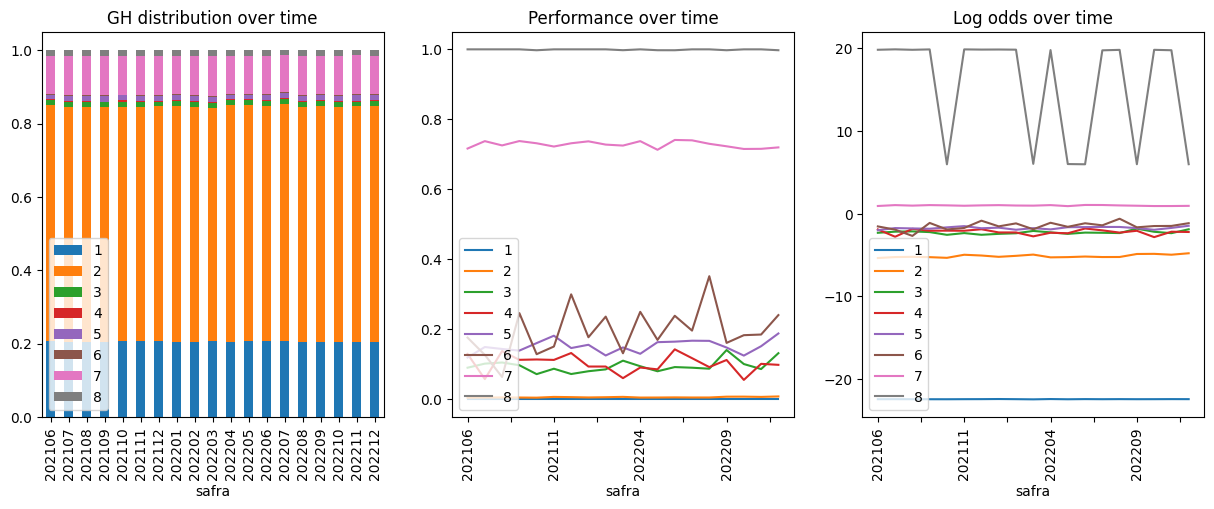

In [13]:
df_data['GH'] = get_gh(df_data,'score',configs[0]['cuts'])
plot_gh(df_data, 'safra', 'target', 'GH', perf_denominator=None)

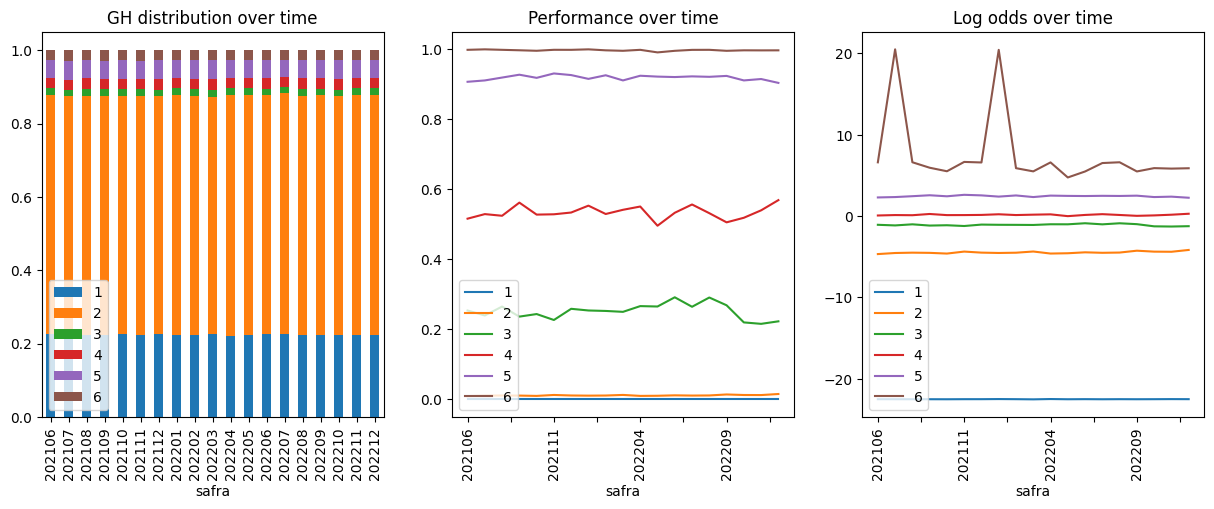

In [14]:
df_data['GH'] = get_gh(df_data,'score',configs[1]['cuts'])
plot_gh(df_data, 'safra', 'target', 'GH', perf_denominator=None)

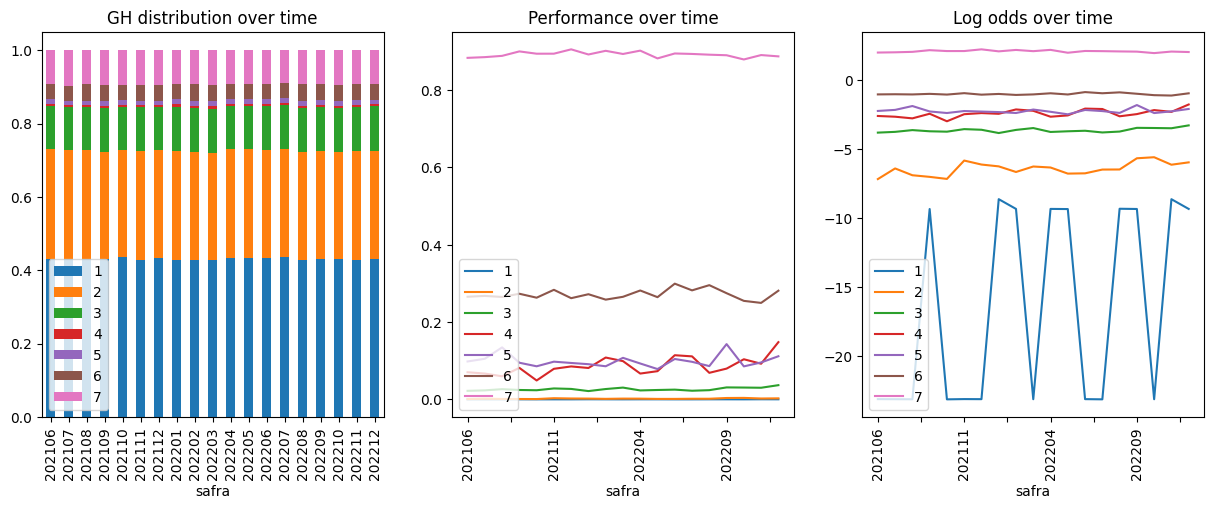

In [15]:
df_data['GH'] = get_gh(df_data,'score',configs[2]['cuts'])
plot_gh(df_data, 'safra', 'target', 'GH', perf_denominator=None)

### SOLUÇÃO 2 - USANDO REGRESSÃO ISOTÔNICA E FORMULANDO COMO OTIMIZAÇÃO CONVEXA

In [16]:
def isotonic_temporal_binning(
    df,
    nm_var_score='score',
    nm_var_reftemp='safra',
    nm_var_target='target',    
    n_prebins=100,
    min_bin_size=0.02,
    smoothing_strength=50,
    max_groups=8
):
    """
    Convex monotonic binning with temporal smoothing.
    
    Returns:
        dict with:
            - cutpoints
            - n_groups
            - bin_table (detailed diagnostics)
    """

    df = df.copy()

    # ---------------------------------------
    # 1. Pre-binning (quantiles)
    # ---------------------------------------
    df["prebin"] = pd.qcut(df[nm_var_score], q=n_prebins, duplicates="drop")

    # numeric bin index
    df["prebin_id"] = df["prebin"].cat.codes

    months = sorted(df[nm_var_reftemp].unique())

    # ---------------------------------------
    # 2. Aggregate stats
    # ---------------------------------------
    stats = (
        df.groupby(["prebin_id", nm_var_reftemp])[nm_var_target]
        .agg(["sum", "count"])
        .reset_index()
    )

    # global rate
    global_rate = df[nm_var_target].mean()

    # ---------------------------------------
    # 3. Compute raw rates
    # ---------------------------------------
    stats["raw_rate"] = stats["sum"] / stats["count"]

    # ---------------------------------------
    # 4. Isotonic regression per month
    # ---------------------------------------
    iso = IsotonicRegression(increasing=True, out_of_bounds="clip")

    stats["iso_rate"] = np.nan

    for m in months:
        mask = stats[nm_var_reftemp] == m

        sub = stats[mask].sort_values("prebin_id")

        x = sub["prebin_id"].values
        y = sub["raw_rate"].values

        # weights = counts (important!)
        w = sub["count"].values

        y_iso = iso.fit_transform(x, y, sample_weight=w)

        stats.loc[mask, "iso_rate"] = y_iso

    # ---------------------------------------
    # 5. Temporal + hierarchical smoothing
    # ---------------------------------------
    # bin-level average across time
    bin_avg = (
        stats.groupby("prebin_id")["iso_rate"]
        .mean()
        .rename("bin_avg")
    )

    stats = stats.merge(bin_avg, on="prebin_id")

    # smoothing
    m = smoothing_strength

    stats["smooth_rate"] = (
        stats["sum"]
        + m * stats["bin_avg"]
        + m * global_rate
    ) / (stats["count"] + 2 * m)

    # ---------------------------------------
    # 6. Collapse across time (final score)
    # ---------------------------------------
    final_bin = (
        stats.groupby("prebin_id")
        .apply(lambda x: np.average(x["smooth_rate"], weights=x["count"]))
        .rename("final_rate")
        .reset_index()
    )

    # enforce monotonicity again (global)
    final_bin = final_bin.sort_values("prebin_id")

    final_bin["final_rate"] = iso.fit_transform(
        final_bin["prebin_id"],
        final_bin["final_rate"]
    )

    # ---------------------------------------
    # 7. Merge bins into groups
    # ---------------------------------------
    # greedy merge based on minimum size
    bin_sizes = (
        df.groupby("prebin_id").size() / len(df)
    )

    groups = []
    current_group = [0]
    current_size = bin_sizes.iloc[0]

    for i in range(1, len(final_bin)):
        size = bin_sizes.iloc[i]

        if current_size + size < min_bin_size:
            current_group.append(i)
            current_size += size
        else:
            groups.append(current_group)
            current_group = [i]
            current_size = size

    groups.append(current_group)

    # limit number of groups
    if len(groups) > max_groups:
        # merge closest groups by rate
        while len(groups) > max_groups:
            diffs = []

            for i in range(len(groups) - 1):
                g1 = groups[i]
                g2 = groups[i + 1]

                r1 = final_bin.loc[g1, "final_rate"].mean()
                r2 = final_bin.loc[g2, "final_rate"].mean()

                diffs.append(abs(r1 - r2))

            idx = np.argmin(diffs)

            groups[idx] = groups[idx] + groups[idx + 1]
            del groups[idx + 1]

    # ---------------------------------------
    # 8. Extract cutpoints
    # ---------------------------------------
    prebin_edges = df["prebin"].cat.categories

    cutpoints = [0.0]

    for g in groups[:-1]:
        last_bin = max(g)
        edge = prebin_edges[last_bin].right
        cutpoints.append(edge)

    cutpoints.append(1.0)

    return {
        "cutpoints": cutpoints,
        "n_groups": len(groups),
        "bin_table": final_bin,
        "groups": groups
    }

In [17]:
result = isotonic_temporal_binning(df_treino,'score','safra','target')

print("Groups:", result["n_groups"])
print("Cutpoints:", np.round(result["cutpoints"], 4))

Groups: 8
Cutpoints: [0.    0.565 0.681 0.743 0.802 0.853 0.892 0.92  1.   ]


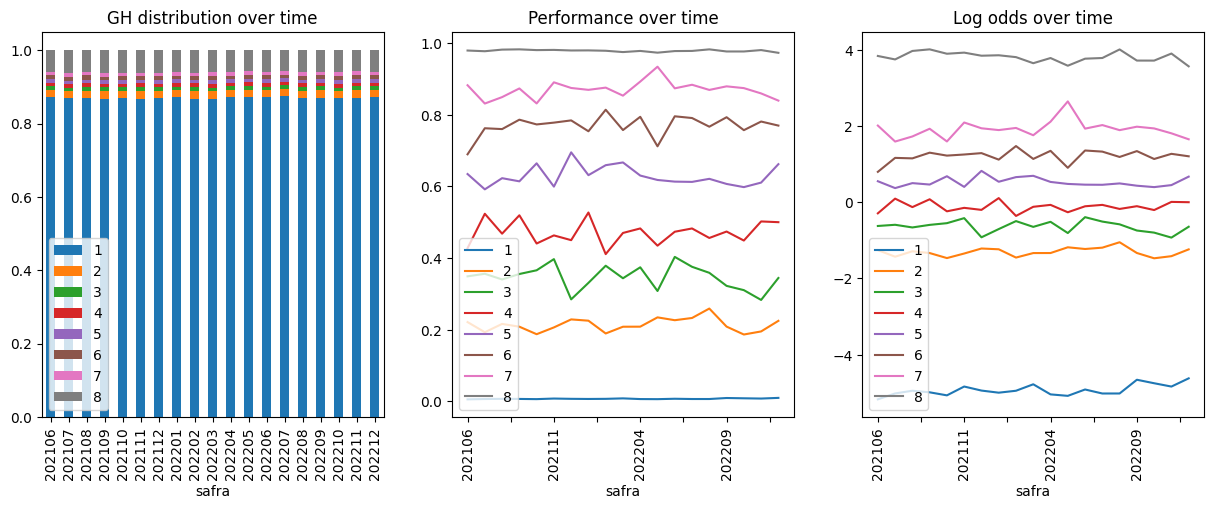

In [18]:
df_data['GH'] = get_gh(df_data,'score',result["cutpoints"])
plot_gh(df_data, 'safra', 'target', 'GH', perf_denominator=None)

### SOLUÇÃO 2.1 - USANDO REGRESSÃO ISOTÔNICA E FORMULANDO COMO OTIMIZAÇÃO CONVEXA
- USANDO DP PARA FORMAÇÃO DOS GRUPOS FINAIS AO INVÉS DE UMA ABORDAGEM GREEDY

In [25]:
def isotonic_temporal_binning_dp(
    df,
    nm_var_score='score',
    nm_var_reftemp='safra',
    nm_var_target='target',
    n_prebins=100,
    min_bin_size=0.02,
    smoothing_strength=50,
    max_groups=8
):

    df = df.copy()

    # ---------------------------------------
    # 1. Pre-binning
    # ---------------------------------------
    df["prebin"] = pd.qcut(df[nm_var_score], q=n_prebins, duplicates="drop")
    df["prebin_id"] = df["prebin"].cat.codes

    months = sorted(df[nm_var_reftemp].unique())

    # ---------------------------------------
    # 2. Aggregate stats
    # ---------------------------------------
    stats = (
        df.groupby(["prebin_id", nm_var_reftemp])[nm_var_target]
        .agg(["sum", "count"])
        .reset_index()
    )

    global_rate = df[nm_var_target].mean()
    stats["raw_rate"] = stats["sum"] / stats["count"]

    # ---------------------------------------
    # 3. Isotonic regression
    # ---------------------------------------
    iso = IsotonicRegression(increasing=True, out_of_bounds="clip")
    stats["iso_rate"] = np.nan

    for m in months:
        sub = stats[stats[nm_var_reftemp] == m].sort_values("prebin_id")

        y_iso = iso.fit_transform(
            sub["prebin_id"],
            sub["raw_rate"],
            sample_weight=sub["count"]
        )

        stats.loc[sub.index, "iso_rate"] = y_iso

    # ---------------------------------------
    # 4. Temporal smoothing
    # ---------------------------------------
    bin_avg = stats.groupby("prebin_id")["iso_rate"].mean().rename("bin_avg")
    stats = stats.merge(bin_avg, on="prebin_id")

    m = smoothing_strength

    stats["smooth_rate"] = (
        stats["sum"]
        + m * stats["bin_avg"]
        + m * global_rate
    ) / (stats["count"] + 2 * m)

    # ---------------------------------------
    # 5. Collapse across time
    # ---------------------------------------
    final_bin = (
        stats.groupby("prebin_id")
        .apply(lambda x: np.average(x["smooth_rate"], weights=x["count"]))
        .rename("final_rate")
        .reset_index()
    )

    final_bin = final_bin.sort_values("prebin_id")

    final_bin["final_rate"] = iso.fit_transform(
        final_bin["prebin_id"],
        final_bin["final_rate"]
    )

    # weights (bin sizes)
    bin_sizes = df.groupby("prebin_id").size().values / len(df)

    rates = final_bin["final_rate"].values
    n = len(rates)

    # ---------------------------------------
    # 6. Precompute segment costs
    # ---------------------------------------
    # cost(i, j) = variance of segment [i, j]
    cost = np.zeros((n, n))

    for i in range(n):
        for j in range(i, n):
            w = bin_sizes[i:j+1]
            r = rates[i:j+1]

            if w.sum() < min_bin_size:
                cost[i, j] = np.inf
                continue

            mean = np.average(r, weights=w)
            var = np.sum(w * (r - mean) ** 2)

            cost[i, j] = var

    # ---------------------------------------
    # 7. Dynamic Programming
    # ---------------------------------------
    K = max_groups

    dp = np.full((K + 1, n), np.inf)
    prev = np.zeros((K + 1, n), dtype=int)

    # base case
    for i in range(n):
        dp[1, i] = cost[0, i]

    # recursion
    for k in range(2, K + 1):
        for i in range(n):
            for j in range(i):
                val = dp[k - 1, j] + cost[j + 1, i]
                if val < dp[k, i]:
                    dp[k, i] = val
                    prev[k, i] = j

    # ---------------------------------------
    # 8. Choose best k
    # ---------------------------------------
    best_k = np.argmin(dp[:, n - 1][1:]) + 1

    # backtrack
    groups = []
    k = best_k
    i = n - 1

    while k > 0:
        j = prev[k, i] if k > 1 else -1
        groups.append(list(range(j + 1, i + 1)))
        i = j
        k -= 1

    groups = list(reversed(groups))

    # ---------------------------------------
    # 9. Extract cutpoints
    # ---------------------------------------
    prebin_edges = df["prebin"].cat.categories

    cutpoints = [0.0]

    for g in groups[:-1]:
        last_bin = max(g)
        edge = prebin_edges[last_bin].right
        cutpoints.append(edge)

    cutpoints.append(1.0)

    return {
        "cutpoints": cutpoints,
        "n_groups": len(groups),
        "groups": groups,
        "bin_table": final_bin
    }

In [26]:
result = isotonic_temporal_binning_dp(df_treino,'score','safra','target')

print("Groups:", result["n_groups"])
print("Cutpoints:", np.round(result["cutpoints"], 4))

Groups: 8
Cutpoints: [0.    0.264 0.427 0.565 0.681 0.802 0.892 0.941 1.   ]


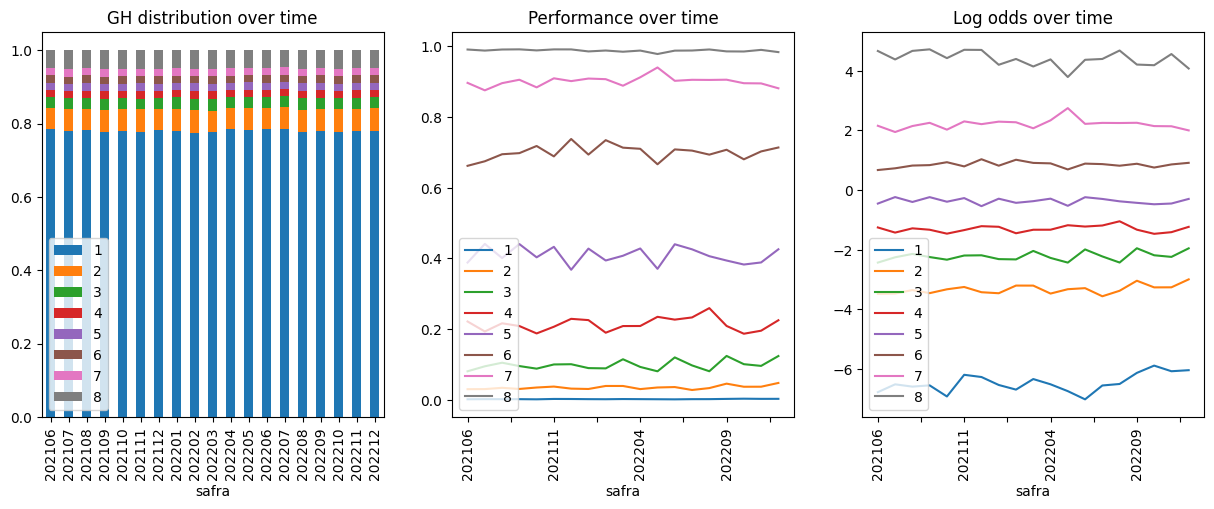

In [27]:
df_data['GH'] = get_gh(df_data,'score',result["cutpoints"])
plot_gh(df_data, 'safra', 'target', 'GH', perf_denominator=None)

In [29]:
result["bin_table"]

,prebin_id,final_rate
0,0,0.013745
1,1,0.013745
2,2,0.013745
3,3,0.013745
4,4,0.013745
...,...,...
95,95,0.847316
96,96,0.860891
97,97,0.870959
98,98,0.874057


### SOLUÇÃO 2.2 - USANDO REGRESSÃO ISOTÔNICA E FORMULANDO COMO OTIMIZAÇÃO CONVEXA
ADICIONADOS:
- OTIMIZAÇÃO DE PSI EMBUTIDA NA MATRIZ DE CUSTOS DO PROCESSO DE DYNAMIC PROGRAMMING
- PENALIZAÇÃO RELATIVA AO ALTO NÚMERO DE GRUPOS
- ESQUEMA QUE EVITA A DEFINIÇÃO DE GRUPOS FINAIS CONTÍGUOS QUE SEJAM ESTATISTICAMENTE INDISTIGUÍVEIS, ATRAVÉS DE UM PARÂMETRO DE SEPARAÇÃO MÍNIMA DAS BAD RATES

In [ ]:
def isotonic_temporal_binning_dp_advanced(
    df,
    nm_var_score='score',
    nm_var_reftemp='safra',
    nm_var_target='target',
    n_prebins=100,
    min_bin_size=0.02,
    smoothing_strength=50,
    max_groups=8,
    lambda_psi=1.0,
    lambda_k=0.01,
    lambda_sep=5.0,
    min_rate_diff=0.005
):

    df = df.copy()

    # ---------------------------------------
    # 1. Pre-binning
    # ---------------------------------------
    df["prebin"] = pd.qcut(df[nm_var_score], q=n_prebins, duplicates="drop")
    df["prebin_id"] = df["prebin"].cat.codes

    months = sorted(df[nm_var_reftemp].unique())

    # ---------------------------------------
    # 2. Aggregate stats
    # ---------------------------------------
    stats = (
        df.groupby(["prebin_id", nm_var_reftemp])[nm_var_target]
        .agg(["sum", "count"])
        .reset_index()
    )

    global_rate = df[nm_var_target].mean()
    stats["raw_rate"] = stats["sum"] / stats["count"]

    # ---------------------------------------
    # 3. Isotonic regression
    # ---------------------------------------
    iso = IsotonicRegression(increasing=True, out_of_bounds="clip")
    stats["iso_rate"] = np.nan

    for m in months:
        sub = stats[stats[nm_var_reftemp] == m].sort_values("prebin_id")

        stats.loc[sub.index, "iso_rate"] = iso.fit_transform(
            sub["prebin_id"],
            sub["raw_rate"],
            sample_weight=sub["count"]
        )

    # ---------------------------------------
    # 4. Temporal smoothing
    # ---------------------------------------
    bin_avg = stats.groupby("prebin_id")["iso_rate"].mean().rename("bin_avg")
    stats = stats.merge(bin_avg, on="prebin_id")

    m = smoothing_strength

    stats["smooth_rate"] = (
        stats["sum"]
        + m * stats["bin_avg"]
        + m * global_rate
    ) / (stats["count"] + 2 * m)

    # ---------------------------------------
    # 5. Collapse across time
    # ---------------------------------------
    final_bin = (
        stats.groupby("prebin_id")
        .apply(lambda x: np.average(x["smooth_rate"], weights=x["count"]))
        .rename("final_rate")
        .reset_index()
        .sort_values("prebin_id")
    )

    final_bin["final_rate"] = iso.fit_transform(
        final_bin["prebin_id"],
        final_bin["final_rate"]
    )

    rates = final_bin["final_rate"].values
    n = len(rates)

    bin_sizes = df.groupby("prebin_id").size().values / len(df)

    # ---------------------------------------
    # PSI helper
    # ---------------------------------------
    def compute_psi(p, q, eps=1e-6):
        p = p + eps
        q = q + eps
        return np.sum((q - p) * np.log(q / p))

    # precompute per-bin per-month distributions
    dist = {}
    for mth in months:
        d = (
            df[df[nm_var_reftemp] == mth]["prebin_id"]
            .value_counts(normalize=True)
            .reindex(range(n), fill_value=0)
            .values
        )
        dist[mth] = d

    # ---------------------------------------
    # 6. Segment cost matrix
    # ---------------------------------------
    cost = np.zeros((n, n))

    for i in range(n):
        for j in range(i, n):

            w = bin_sizes[i:j+1]
            r = rates[i:j+1]

            if w.sum() < min_bin_size:
                cost[i, j] = np.inf
                continue

            # variance term
            mean = np.average(r, weights=w)
            var = np.sum(w * (r - mean) ** 2)

            # PSI term
            psi_total = 0
            base = None

            for idx, mth in enumerate(months):
                seg_dist = dist[mth][i:j+1]
                seg_dist = seg_dist / (seg_dist.sum() + 1e-6)

                if idx == 0:
                    base = seg_dist
                else:
                    psi_total += compute_psi(base, seg_dist)

            psi_avg = psi_total / max(1, len(months) - 1)




            # separation term
            sep_total = 0
            base = None

            for idx, mth in enumerate(months):
                seg_dist = dist[mth][i:j+1]
                seg_dist = seg_dist / (seg_dist.sum() + 1e-6)

                if idx == 0:
                    base = seg_dist
                else:
                    psi_total += compute_psi(base, seg_dist)

            psi_avg = psi_total / max(1, len(months) - 1)




            cost[i, j] = var + lambda_psi * psi_avg

    # ---------------------------------------
    # 7. DP with penalties
    # ---------------------------------------
    K = max_groups

    dp = np.full((K + 1, n), np.inf)
    prev = np.zeros((K + 1, n), dtype=int)

    for i in range(n):
        dp[1, i] = cost[0, i]

    for k in range(2, K + 1):
        for i in range(n):
            for j in range(i):
                val = dp[k - 1, j] + cost[j + 1, i]
                if val < dp[k, i]:
                    dp[k, i] = val
                    prev[k, i] = j

    # ---------------------------------------
    # 8. Select best k (with penalty)
    # ---------------------------------------
    best_k = None
    best_val = np.inf

    for k in range(1, K + 1):
        val = dp[k, n - 1] + lambda_k * k
        if val < best_val:
            best_val = val
            best_k = k

    # ---------------------------------------
    # 9. Backtrack
    # ---------------------------------------
    groups = []
    k = best_k
    i = n - 1

    while k > 0:
        j = prev[k, i] if k > 1 else -1
        groups.append(list(range(j + 1, i + 1)))
        i = j
        k -= 1

    groups = list(reversed(groups))

    # ---------------------------------------
    # 10. Separation enforcement
    # ---------------------------------------
    def group_rate(g):
        w = bin_sizes[g]
        r = rates[g]
        return np.average(r, weights=w)

    merged = True
    while merged:
        merged = False
        new_groups = []

        i = 0
        while i < len(groups):
            if i < len(groups) - 1:
                r1 = group_rate(groups[i])
                r2 = group_rate(groups[i + 1])

                if abs(r2 - r1) < min_rate_diff:
                    groups[i] = groups[i] + groups[i + 1]
                    del groups[i + 1]
                    merged = True
                    break

            i += 1

    # ---------------------------------------
    # 11. Extract cutpoints
    # ---------------------------------------
    prebin_edges = df["prebin"].cat.categories

    cutpoints = [0.0]
    for g in groups[:-1]:
        edge = prebin_edges[max(g)].right
        cutpoints.append(edge)
    cutpoints.append(1.0)

    return {
        "cutpoints": cutpoints,
        "n_groups": len(groups),
        "groups": groups,
        "bin_table": final_bin,
        "objective_value": best_val
    }

In [72]:
result = isotonic_temporal_binning_dp_advanced(df_treino,'score','safra','target')

print("Groups:", result["n_groups"])
print("Cutpoints:", np.round(result["cutpoints"], 4))

Groups: 1
Cutpoints: [0. 1.]


In [ ]:
df_data['GH'] = get_gh(df_data,'score',result["cutpoints"])
plot_gh(df_data, 'safra', 'target', 'GH', perf_denominator=None)